In [1]:
RECOMPUTE_FULL = False


In [2]:
import numpy as np
import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from scipy.signal import welch, spectrogram as sp_spectrogram
from scipy.signal import hilbert, butter, filtfilt
from scipy.special import erf as sc_erf
from scipy.optimize import curve_fit
import math, os, time, pickle

BASE   = "data"
FIGDIR = os.path.join("figures_gamma", "03")
os.makedirs(FIGDIR, exist_ok=True)

In [3]:
##generate a noise
def ornstein_uhlenbeck(mu, sigma, theta, dt, T, x0):
    num_steps = int(T / dt)
    t = np.linspace(0, T, num_steps + 1)
    x = np.zeros(num_steps + 1)
    x[0] = x0
    for i in range(1, num_steps + 1):
        dW = np.random.normal(0, np.sqrt(dt))
        x[i] = x[i - 1] + theta * (mu - x[i - 1]) * dt + sigma * dW
    return t, x

mu = 0.
sigma = 10
theta = 200
dt = 0.0001
T_duration = 4
x0 = 0.0

tf, xf = ornstein_uhlenbeck(mu, sigma, theta, dt, T_duration, x0)
xf = xf[:-1]

In [4]:
# Chargement des fonctions de transfert
PRS = np.load(os.path.join(BASE, "RS-cell_CONFIG1_fit.npy"))[[0,1,2,3,5,8,9,6,10,7]]
PFS = np.load(os.path.join(BASE, "FS-cell_CONFIG1_fit.npy"))[[0,1,2,3,5,8,9,6,10,7]]

# Parametres neuronaux 
Gl=10e-9; Cm=200e-12; El=-65e-3; Ee=0.; Ei=-80e-3
bRS=60e-12; a=4e-9; twRS=0.5
Qe=1.25e-9; Qi=5e-9; Ti=5e-3; Te=5e-3; tau_l=0.003

# Parametres reseau
pconnec=0.05; gei=0.2; Ntot=10000
T=0.005; epsilon=0.05
input_to_exc=4.; input_to_inh=4.

def TF(P, fexc, finh, adapt, El_):
    fe=fexc*(1.-gei)*pconnec*Ntot; fi=finh*gei*pconnec*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG; Tm=Cm/muG
    Ue=Qe/muG*(Ee-muV); Ui=Qi/muG*(Ei-muV)
    sV2=fe*(Ue*Te)**2/2./(Te+Tm)+fi*(Ui*Ti)**2/2./(Ti+Tm)
    sV=math.sqrt(max(sV2,0.))+1e-12
    fe+=1e-9; fi+=1e-9
    num=fe*(Ue*Te)**2+fi*(Ui*Ti)**2
    den=fe*(Ue*Te)**2/(Te+Tm)+fi*(Ui*Ti)**2/(Ti+Tm)  
    TvN=max((num/den if den>1e-20 else 0.5)*Gl/Cm, 1e-6)
    mu0=-60e-3; Dmu=10e-3; s0=4e-3; Ds=6e-3; Tv0=0.5; DTv=1.
    vthr=(P[0]+P[1]*(muV-mu0)/Dmu+P[2]*(sV-s0)/Ds+P[3]*(TvN-Tv0)/DTv
         +P[4]*((muV-mu0)/Dmu)**2+P[5]*(muV-mu0)/Dmu*(sV-s0)/Ds
         +P[6]*(muV-mu0)/Dmu*(TvN-Tv0)/DTv+P[7]*((sV-s0)/Ds)**2
         +P[8]*(sV-s0)/Ds*(TvN-Tv0)/DTv+P[9]*((TvN-Tv0)/DTv)**2)
    return float(max(0.5/TvN*Gl/Cm*(1.-sc_erf((vthr-muV)/(math.sqrt(2.)*sV))), 1e-9))

def MFw(fexc, finh, adapt, ff, El_):
    fe=fexc*(1.-gei)*pconnec*Ntot; fi=finh*gei*pconnec*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG
    return -adapt/twRS+bRS*ff+a*(muV-El_)/twRS


Low gamma  Ele=-68mV  Eli=-58mV ...


High gamma  Ele=-58mV  Eli=-72mV ...


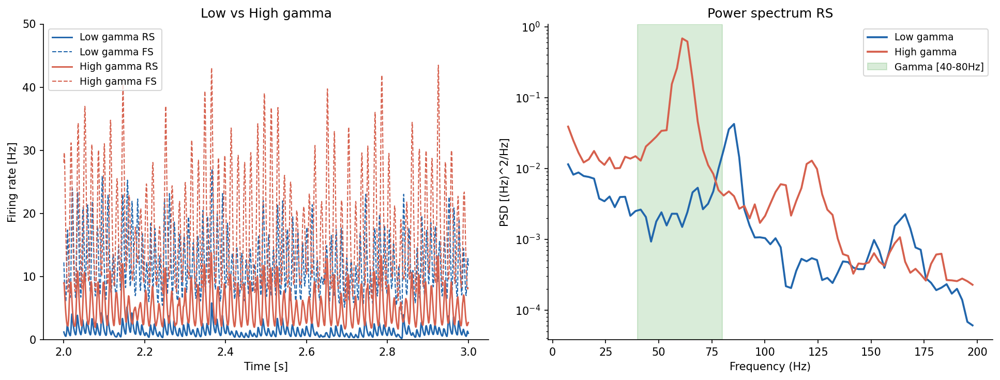

In [5]:
STATES = {
    "Low gamma" : dict(Ele=-68e-3, Eli=-58e-3, color="#2166AC"),
    "High gamma": dict(Ele=-58e-3, Eli=-72e-3, color="#D6604D"),
}

tfinal=4; tsteps=int(tfinal/dt); t=np.linspace(0,tfinal,tsteps)

traces={}
for label,cfg in STATES.items():
    Ele=cfg["Ele"]; Eli=cfg["Eli"]
    print(f"{label}  Ele={Ele*1e3:.0f}mV  Eli={Eli*1e3:.0f}mV ...",flush=True)
    w=1e-10; fecont=1.; ficont=1.
    LSw=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfe=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt))); LSfi=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),len(t)):
        fecont+=dt/T*(TF(PRS,LSfe[i-tau_e_d]+xf[i]+input_to_exc,LSfi[i-tau_i_d],LSw[i],Ele)-LSfe[i])
        ficont+=dt/T*(TF(PFS,LSfe[i-tau_i_d]+xf[i]+input_to_inh,LSfi[i-tau_e_d],0.,Eli)-LSfi[i])
        w+=dt*MFw(LSfe[i],LSfi[i],LSw[i],LSfe[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe.append(float(fecont)); LSfi.append(float(ficont)); LSw.append(float(w))
    LSfe.pop(0); LSfi.pop(0); LSw.pop(0)
    traces[label]=dict(LSfe=LSfe,LSfi=LSfi,LSw=LSw,**cfg)
    sl=slice(int(2/dt),int(3/dt))

# Figure firing rate
sl=slice(int(2/dt),int(3/dt)); t_sl=t[sl]
fig,axes=plt.subplots(1,2,figsize=(13,5),dpi=150)
fig.patch.set_facecolor("white")
for label,d in traces.items():
    fe=np.array(d["LSfe"])[sl]; fi=np.array(d["LSfi"])[sl]; col=d["color"]
    axes[0].plot(t_sl,fe,color=col,lw=1.4,label=f"{label} RS")
    axes[0].plot(t_sl,fi,color=col,lw=1.0,ls='--',label=f"{label} FS")
axes[0].set_xlabel("Time [s]"); axes[0].set_ylabel("Firing rate [Hz]")
axes[0].set_title("Low vs High gamma"); axes[0].legend(fontsize=9)
axes[0].set_ylim(0,50); axes[0].spines[['top','right']].set_visible(False)

# PSD
half=len(t)//2
for label,d in traces.items():
    sig=np.array(d["LSfe"])[half:]-np.mean(np.array(d["LSfe"])[half:])
    freqs,psd=welch(sig,fs=int(1/dt),nperseg=4096)
    mask=(freqs>5)&(freqs<200)
    axes[1].semilogy(freqs[mask],psd[mask],color=d["color"],lw=1.8,label=label)
axes[1].axvspan(40,80,alpha=0.15,color='green',label='Gamma [40-80Hz]')
axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("PSD [(Hz)^2/Hz]")
axes[1].set_title("Power spectrum RS"); axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
fpath=os.path.join(FIGDIR,"FIG_firing_rate_v4.png")
fig.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')

In [6]:
SIGMAS=[5,10,30,60]; AMP=0.9; SEED=42; N_STIM=200; SPACING=1.2
T_TOTAL=N_STIM*SPACING+2.0; N_STEPS=int(T_TOTAL/dt)
t_sta=np.arange(N_STEPS)*dt
T_STIM=1.0+np.arange(N_STIM)*SPACING
W_PRE=0.200; W_POST=0.600
N_PRE=int(W_PRE/dt); N_POST=int(W_POST/dt); N_WIN=N_PRE+N_POST
t_win=np.arange(-N_PRE,N_POST)*dt*1000  # ms
pre_sl=(t_win>=-200)&(t_win<-50)
ep_sl=(t_win>=0)&(t_win<=200)

=== G per-trial (mean amp High / mean amp Low) + t-test 
  sigma= 5ms  G_fe=0.872 OK (t=-0.83 p=0.405 ns)  G_fi=1.509 !! (t=+2.61 p=0.0095 **)  G_fc=0.948 OK (t=-0.33 p=0.739 ns)  


  sigma=10ms  G_fe=0.653 OK (t=-2.53 p=0.0119 *)  G_fi=1.329 !! (t=+1.72 p=0.087 ns)  G_fc=0.732 OK (t=-1.88 p=0.0613 ns)  
  sigma=30ms  G_fe=0.553 OK (t=-3.42 p=0.000712 ***)  G_fi=1.177 !! (t=+0.99 p=0.323 ns)  G_fc=0.624 OK (t=-2.79 p=0.00555 **)  


  sigma=60ms  G_fe=0.552 OK (t=-2.93 p=0.00355 **)  G_fi=1.151 !! (t=+0.75 p=0.457 ns)  G_fc=0.621 OK (t=-2.42 p=0.0158 *)  


C:\Users\fayre\AppData\Local\Temp\ipykernel_19992\3732869623.py:159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,1,0.97])


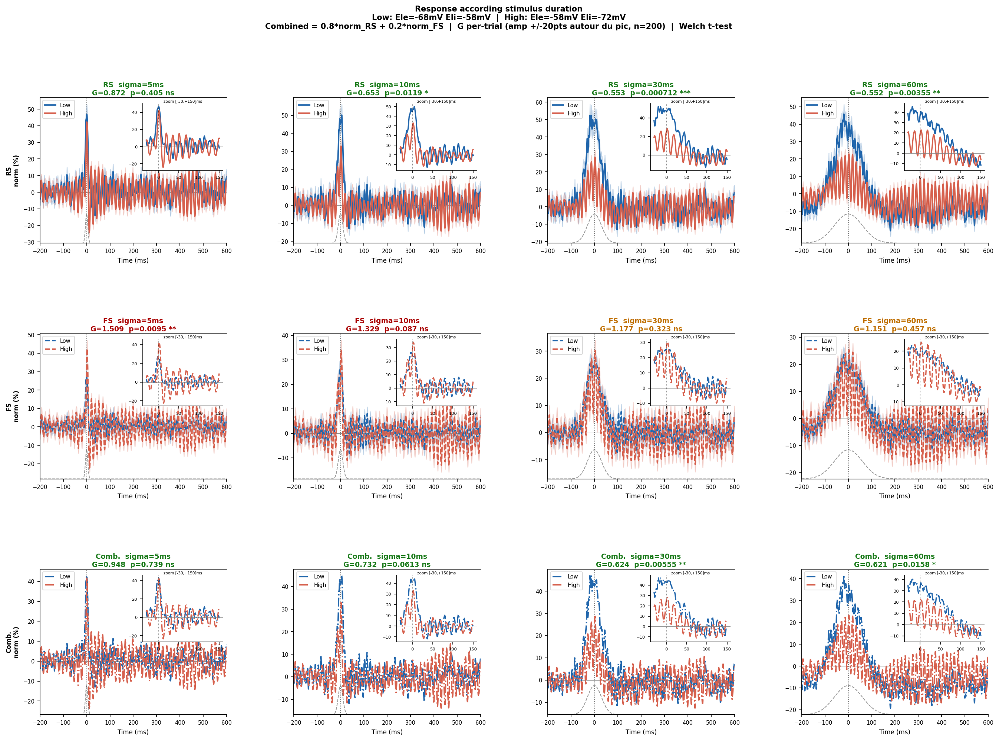

In [7]:
def run_sta_full(Ele, Eli, sig_ms, seed=SEED):
    imp=np.zeros(N_STEPS)
    for ts in T_STIM:
        imp+=AMP*np.exp(-0.5*((t_sta-ts)/(sig_ms*1e-3))**2)
    np.random.seed(seed)
    _, xf_s = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOTAL,x0); xf_s=xf_s[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_s=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfi_s=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_s=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_STEPS); fi_out=np.zeros(N_STEPS)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_STEPS):
        inp=xf_s[i]+input_to_exc+imp[i]
        fecont+=dt/T*(TF(PRS,LSfe_s[i-tau_e_d]+inp,LSfi_s[i-tau_i_d],LSw_s[i],Ele)-LSfe_s[i])
        ficont+=dt/T*(TF(PFS,LSfe_s[i-tau_i_d]+inp,LSfi_s[i-tau_e_d],0.,Eli)-LSfi_s[i])
        w+=dt*MFw(LSfe_s[i],LSfi_s[i],LSw_s[i],LSfe_s[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_s.append(float(fecont)); LSfi_s.append(float(ficont)); LSw_s.append(float(w))
        fe_out[i]=fecont; fi_out[i]=ficont
    def extract(sig):
        wins=[sig[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST]
              for ts in T_STIM if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_STEPS]
        wins=np.array(wins)
        return wins.mean(axis=0),wins.std(axis=0,ddof=1)/np.sqrt(len(wins)),wins
    sta_fe_m,sta_fe_s,wins_fe=extract(fe_out); sta_fi_m,sta_fi_s,wins_fi=extract(fi_out)
    b_fe=float(sta_fe_m[pre_sl].mean()); b_fi=float(sta_fi_m[pre_sl].mean())
    ep_fe=float(sta_fe_m[ep_sl].max())-b_fe; ep_fi=float(sta_fi_m[ep_sl].max())-b_fi
    return dict(sta_fe=sta_fe_m,sem_fe=sta_fe_s,base_fe=b_fe,ep_fe=ep_fe,
                sta_fi=sta_fi_m,sem_fi=sta_fi_s,base_fi=b_fi,ep_fi=ep_fi,
                trials_fe=wins_fe,trials_fi=wins_fi,n_trials=len(wins_fe))

CACHE_V5=os.path.join(BASE,"sta_results_v5_trials.pkl")
t0=time.time(); results={}
if os.path.exists(CACHE_V5):
    with open(CACHE_V5,"rb") as f: results=pickle.load(f)
else:
    for sname,cfg in STATES.items():
        results[sname]={}
        for sig in SIGMAS:
            print(f"  {sname} sigma={sig}ms ...",flush=True)
            results[sname][sig]=run_sta_full(cfg["Ele"],cfg["Eli"],sig)
    with open(CACHE_V5,"wb") as f: pickle.dump(results,f)

_n=len(results[list(results.keys())[0]][SIGMAS[0]]["sta_fe"])
if _n!=N_WIN:
    t_win=np.arange(-N_PRE,_n-N_PRE)*dt*1000
    pre_sl=(t_win>=-200)&(t_win<-50)
    ep_sl=(t_win>=0)&(t_win<=200)
    print(f"t_win adapte: {len(t_win)} pts")



from scipy.stats import ttest_ind

C_LOW="#2166AC"; C_HIGH="#D6604D"
lat_sl=(t_win>=0)&(t_win<=150)
HW=20

def p_stars(p):
    if np.isnan(p): return "n/a"
    return "***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else "ns"

def amp_pertrial(wins):
    m=wins.mean(axis=0); idx=np.where(lat_sl)[0]
    it=int(idx[np.argmax(m[lat_sl])])
    lo=max(0,it-HW); hi=min(wins.shape[1],it+HW+1)
    return wins[:,lo:hi].mean(axis=1)-wins[:,pre_sl].mean(axis=1), float(t_win[it])

def welch_p(a,b):
    a=np.asarray(a,float); b=np.asarray(b,float)
    if a.size<3 or b.size<3: return float("nan"), float("nan")
    t,p=ttest_ind(a,b,equal_var=False); return float(t),float(p)

def amp_norm_pt(d, pop):
    a,lat=amp_pertrial(np.asarray(d[f"trials_{pop}"]))
    return a/max(abs(d[f"base_{pop}"]),1e-9)*100, lat

def amp_norm_pt_comb(d, we=0.8, wi=0.2):
    tre=(np.asarray(d["trials_fe"])-d["base_fe"])/max(abs(d["base_fe"]),1e-9)*100
    tri=(np.asarray(d["trials_fi"])-d["base_fi"])/max(abs(d["base_fi"]),1e-9)*100
    a,lat=amp_pertrial(we*tre+wi*tri)
    return a,lat

G_rel={}
print("=== G per-trial (mean amp High / mean amp Low) + t-test ")
for sig in SIGMAS:
    hi=results["High gamma"][sig]; lo=results["Low gamma"][sig]
    a_fe_lo,lat_fe_lo=amp_norm_pt(lo,"fe"); a_fe_hi,lat_fe_hi=amp_norm_pt(hi,"fe")
    a_fi_lo,_=amp_norm_pt(lo,"fi");         a_fi_hi,_=amp_norm_pt(hi,"fi")
    a_fc_lo,_=amp_norm_pt_comb(lo);         a_fc_hi,_=amp_norm_pt_comb(hi)
    G_fe=a_fe_hi.mean()/max(a_fe_lo.mean(),1e-9)
    G_fi=a_fi_hi.mean()/max(a_fi_lo.mean(),1e-9)
    G_fc=a_fc_hi.mean()/max(a_fc_lo.mean(),1e-9)
    t_fe,p_fe=welch_p(a_fe_hi,a_fe_lo)
    t_fi,p_fi=welch_p(a_fi_hi,a_fi_lo)
    t_fc,p_fc=welch_p(a_fc_hi,a_fc_lo)
    G_rel[sig]=dict(G_fe=G_fe,G_fi=G_fi,G_fc=G_fc,
                    p_fe=p_fe,p_fi=p_fi,p_fc=p_fc,
                    lat_lo=lat_fe_lo,lat_hi=lat_fe_hi)
    print(f"  sigma={sig:2d}ms  "
          f"G_fe={G_fe:.3f} {'OK' if G_fe<1 else '!!'} (t={t_fe:+.2f} p={p_fe:.3g} {p_stars(p_fe)})  "
          f"G_fi={G_fi:.3f} {'OK' if G_fi<1 else '!!'} (t={t_fi:+.2f} p={p_fi:.3g} {p_stars(p_fi)})  "
          f"G_fc={G_fc:.3f} {'OK' if G_fc<1 else '!!'} (t={t_fc:+.2f} p={p_fc:.3g} {p_stars(p_fc)})  ")


def norm_pct(arr,base):
    return (arr-base)/max(abs(base),1e-9)*100

fig=plt.figure(figsize=(5.5*len(SIGMAS),4.8*3),dpi=150)
fig.patch.set_facecolor("white")
gs=gridspec.GridSpec(3,len(SIGMAS),figure=fig,hspace=0.62,wspace=0.36)

for col,sig in enumerate(SIGMAS):
    imp_disp=AMP*np.exp(-0.5*(t_win/sig)**2)
    d=G_rel[sig]
    hi=results["High gamma"][sig]; lo=results["Low gamma"][sig]
    nfe_lo=norm_pct(np.asarray(lo["sta_fe"]),lo["base_fe"])
    nfi_lo=norm_pct(np.asarray(lo["sta_fi"]),lo["base_fi"])
    nfe_hi=norm_pct(np.asarray(hi["sta_fe"]),hi["base_fe"])
    nfi_hi=norm_pct(np.asarray(hi["sta_fi"]),hi["base_fi"])
    nfc_lo=0.8*nfe_lo+0.2*nfi_lo; nfc_hi=0.8*nfe_hi+0.2*nfi_hi
    row_data=[
        ("RS",   nfe_lo,nfe_hi,d["G_fe"],d["p_fe"],"-",  "sem_fe","base_fe"),
        ("FS",   nfi_lo,nfi_hi,d["G_fi"],d["p_fi"],"--", "sem_fi","base_fi"),
        ("Comb.",nfc_lo,nfc_hi,d["G_fc"],d["p_fc"],"-.",None,None),
    ]
    for row,(pop,m_lo,m_hi,G,pval,ls,sem_k,base_k) in enumerate(row_data):
        ax=fig.add_subplot(gs[row,col])
        gcol="#1a7a1a" if G<1 else ("#c07000" if G<1.3 else "#aa0000")
        ax.plot(t_win,m_lo,color=C_LOW,lw=1.8,ls=ls,label="Low",zorder=3)
        ax.plot(t_win,m_hi,color=C_HIGH,lw=1.8,ls=ls,label="High",zorder=3)
        if sem_k:
            s_lo=np.asarray(lo[sem_k])/max(abs(lo[base_k]),1e-9)*100
            s_hi=np.asarray(hi[sem_k])/max(abs(hi[base_k]),1e-9)*100
            ax.fill_between(t_win,m_lo-s_lo,m_lo+s_lo,color=C_LOW,alpha=0.18,zorder=2)
            ax.fill_between(t_win,m_hi-s_hi,m_hi+s_hi,color=C_HIGH,alpha=0.18,zorder=2)
        axt=ax.twinx(); axt.plot(t_win,imp_disp,"k--",lw=1.0,alpha=0.4)
        axt.set_ylim(0,AMP*5); axt.set_yticks([]); axt.spines["right"].set_visible(False)
        ax.axvline(0,color="k",ls=":",lw=0.9,alpha=0.55); ax.axhline(0,color="gray",lw=0.5)
        ax.set_xlim(-200,600); ax.set_xlabel("Time (ms)",fontsize=8)
        ax.tick_params(labelsize=7); ax.spines[["top","right"]].set_visible(False)
        ax.legend(fontsize=7,loc="upper left",framealpha=0.7)
        ax.set_title(f"{pop}  sigma={sig}ms\nG={G:.3f}  p={pval:.3g} {p_stars(pval)}",
                     fontsize=9,fontweight="bold",color=gcol,pad=3)
        if col==0: ax.set_ylabel(f"{pop}\nnorm (%)",fontsize=8,fontweight="bold")
        axins=ax.inset_axes([0.55,0.50,0.43,0.46])
        zsl=(t_win>=-30)&(t_win<=150)
        axins.plot(t_win[zsl],m_lo[zsl],color=C_LOW,lw=1.6,ls=ls)
        axins.plot(t_win[zsl],m_hi[zsl],color=C_HIGH,lw=1.6,ls=ls)
        axins.axvline(0,color="k",ls=":",lw=0.7,alpha=0.5); axins.axhline(0,color="gray",lw=0.4)
        axins.tick_params(labelsize=5.5); axins.set_title("zoom [-30,+150]ms",fontsize=5,pad=1.5)
        axins.spines[["top","right"]].set_visible(False)

fig.suptitle(f"Response according stimulus duration\n"
             "Low: Ele=-68mV Eli=-58mV  |  High: Ele=-58mV Eli=-72mV\n"
             "Combined = 0.8*norm_RS + 0.2*norm_FS  |  G per-trial (amp +/-20pts autour du pic, n=200)  |  Welch t-test",
             fontsize=10,fontweight="bold",x=0.5,y=0.995)
plt.tight_layout(rect=[0,0,1,0.97])
fpath=os.path.join(FIGDIR,"FIG_sta_v5_pertrial.png")
fig.savefig(fpath,dpi=150,bbox_inches="tight",facecolor="white")


=== Input asymetrique sigma=10ms ===
  factor=0.1x  G_fe=1.807 !!  G_fi=1.402 !!  G_fc=1.694 !!
  factor=0.2x  G_fe=1.007 !!  G_fi=1.054 !!  G_fc=1.018 !!
  factor=0.3x  G_fe=1.482 !!  G_fi=1.18 !!  G_fc=1.402 !!
  factor=0.4x  G_fe=1.062 !!  G_fi=0.887 OK  G_fc=1.009 !!
  factor=0.5x  G_fe=0.395 OK  G_fi=0.465 OK  G_fc=0.412 OK
  factor=0.6x  G_fe=0.249 OK  G_fi=0.228 OK  G_fc=0.245 OK
  factor=0.7x  G_fe=0.542 OK  G_fi=0.657 OK  G_fc=0.566 OK
  factor=0.8x  G_fe=0.365 OK  G_fi=0.57 OK  G_fc=0.404 OK
  factor=0.9x  G_fe=0.527 OK  G_fi=0.969 OK  G_fc=0.586 OK
  factor=1.0x  G_fe=0.655 OK  G_fi=1.374 !!  G_fc=0.734 OK
  factor=1.1x  G_fe=0.399 OK  G_fi=1.002 !!  G_fc=0.454 OK
  factor=1.2x  G_fe=0.505 OK  G_fi=1.485 !!  G_fc=0.575 OK
  factor=1.3x  G_fe=0.438 OK  G_fi=1.495 !!  G_fc=0.495 OK
  factor=1.4x  G_fe=0.46 OK  G_fi=1.272 !!  G_fc=0.499 OK
  factor=1.5x  G_fe=0.451 OK  G_fi=1.479 !!  G_fc=0.489 OK
  factor=1.6x  G_fe=0.398 OK  G_fi=1.437 !!  G_fc=0.426 OK
  factor=1.7x  G_fe=0.

Figure: figures_gamma\03\FIG_asym_v4.png





In [8]:
ASYM_FACTORS=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2]; SIGMA_ASYM=10
N_STIM_A=200; SPACING_A=1.2; T_TOTAL_A=N_STIM_A*SPACING_A+2.0
N_STEPS_A=int(T_TOTAL_A/dt); t_sta_A=np.arange(N_STEPS_A)*dt
T_STIM_A=1.0+np.arange(N_STIM_A)*SPACING_A
pre_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=-200)&(np.arange(-N_PRE,N_POST)*dt*1000<-50)
ep_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=0)&(np.arange(-N_PRE,N_POST)*dt*1000<=200)

def run_sta_asym_inh(Ele,Eli,sig_ms,asym_factor,seed=SEED):
    imp=np.zeros(N_STEPS_A)
    for ts in T_STIM_A:
        imp+=AMP*np.exp(-0.5*((t_sta_A-ts)/(sig_ms*1e-3))**2)
    np.random.seed(seed)
    _, xf_a = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOTAL_A,x0); xf_a=xf_a[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_a=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfi_a=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_a=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_STEPS_A); fi_out=np.zeros(N_STEPS_A)
    inp_inh=asym_factor*input_to_exc
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_STEPS_A):
        ie=xf_a[i]+input_to_exc+imp[i]; ii=xf_a[i]+inp_inh+imp[i]
        fecont+=dt/T*(TF(PRS,LSfe_a[i-tau_e_d]+ie,LSfi_a[i-tau_i_d],LSw_a[i],Ele)-LSfe_a[i])
        ficont+=dt/T*(TF(PFS,LSfe_a[i-tau_i_d]+ii,LSfi_a[i-tau_e_d],0.,Eli)-LSfi_a[i])
        w+=dt*MFw(LSfe_a[i],LSfi_a[i],LSw_a[i],LSfe_a[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_a.append(float(fecont)); LSfi_a.append(float(ficont)); LSw_a.append(float(w))
        fe_out[i]=fecont; fi_out[i]=ficont
    def extr(sig):
        wins=[sig[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST]
              for ts in T_STIM_A if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_STEPS_A]
        wins=np.array(wins); m=wins.mean(axis=0); s=wins.std(axis=0,ddof=1)/np.sqrt(len(wins))
        return m,s
    fe_m,fe_s=extr(fe_out); fi_m,fi_s=extr(fi_out)
    b_fe=float(fe_m[pre_sl_A].mean()); b_fi=float(fi_m[pre_sl_A].mean())
    return dict(sta_fe=fe_m,sem_fe=fe_s,base_fe=b_fe,ep_fe=float(fe_m[ep_sl_A].max())-b_fe,
                sta_fi=fi_m,sem_fi=fi_s,base_fi=b_fi,ep_fi=float(fi_m[ep_sl_A].max())-b_fi)


results_asym={}
for fac in ASYM_FACTORS:
    CACHE_A=os.path.join(BASE,'cache_asym_v4_'+str(fac)+'.pkl')
    CACHE_A=os.path.join(BASE,'cache_asym_v4_{:.1f}.pkl'.format(fac))
    if os.path.exists(CACHE_A):
        with open(CACHE_A,'rb') as f: results_asym[fac]=pickle.load(f)
    else:
        results_asym[fac]={}
        for label,cfg in STATES.items():
            print('  '+label+' factor='+str(fac)+'x ...',flush=True)
            results_asym[fac][label]=run_sta_asym_inh(cfg['Ele'],cfg['Eli'],SIGMA_ASYM,fac)
        with open(CACHE_A,'wb') as f: pickle.dump(results_asym[fac],f)

# G normalise = (ep/base_High) / (ep/base_Low)
G_asym={}
print('=== Input asymetrique sigma=' + str(SIGMA_ASYM) + 'ms ===')
for fac in ASYM_FACTORS:
    lo=results_asym[fac]['Low gamma']; hi=results_asym[fac]['High gamma']
    G_fe=(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))/(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))
    G_fi=(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))/(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_lo=0.8*(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))+0.2*(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_hi=0.8*(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))+0.2*(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))
    G_fc=ep_fc_hi/max(ep_fc_lo,1e-9)
    G_asym[fac]=dict(G_fe=G_fe,G_fi=G_fi,G_fc=G_fc)
    sfe='OK' if G_fe<1 else '!!'
    sfi='OK' if G_fi<1 else '!!'
    sfc='OK' if G_fc<1 else '!!'
    print('  factor='+str(fac)+'x  G_fe='+str(round(G_fe,3))+' '+sfe+'  G_fi='+str(round(G_fi,3))+' '+sfi+'  G_fc='+str(round(G_fc,3))+' '+sfc)

C_LOW='#2166AC'; C_HIGH='#D6604D'
fig,axes=plt.subplots(3,len(ASYM_FACTORS),figsize=(5*len(ASYM_FACTORS),10),dpi=150)
fig.patch.set_facecolor('white')
row_cfg=[('RS','sta_fe','sem_fe','base_fe'),('FS','sta_fi','sem_fi','base_fi')]
for col,fac in enumerate(ASYM_FACTORS):
    G_fc=G_asym[fac]['G_fc']; gcol='#1a7a1a' if G_fc<1 else '#aa0000'
    for row,(pop,key,sem_key,bkey) in enumerate(row_cfg):
        ax=axes[row,col]
        lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
        for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
            m=norm_pct(np.asarray(d[key]),d[bkey])
            s=np.asarray(d[sem_key])/max(abs(d[bkey]),1e-9)*100
            ax.plot(t_win,m,color=color,lw=1.8,label=label)
            ax.fill_between(t_win,m-s,m+s,color=color,alpha=0.18)
        ax.axvline(0,color='k',ls=':',lw=0.8); ax.axhline(0,color='gray',lw=0.4)
        ax.set_xlim(-100,400); ax.set_xlabel('Time (ms)',fontsize=8)
        ax.legend(fontsize=7); ax.spines[['top','right']].set_visible(False)
        if row==0: ax.set_title('factor='+str(fac)+'x  G_fc='+str(round(G_fc,3)),fontsize=9,color=gcol,fontweight='bold')
        if col==0: ax.set_ylabel(pop+' norm. (%)',fontsize=9,fontweight='bold')
    ax2=axes[2,col]
    lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
    for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
        nfe=norm_pct(np.asarray(d['sta_fe']),d['base_fe'])
        nfi=norm_pct(np.asarray(d['sta_fi']),d['base_fi'])
        ax2.plot(t_win,0.8*nfe+0.2*nfi,color=color,lw=1.8,ls='-.',label=label)
    ax2.axvline(0,color='k',ls=':',lw=0.8); ax2.axhline(0,color='gray',lw=0.4)
    ax2.set_xlim(-100,400); ax2.set_xlabel('Time (ms)',fontsize=8)
    ax2.legend(fontsize=7); ax2.spines[['top','right']].set_visible(False)
    if col==0: ax2.set_ylabel('Combined norm. (%)',fontsize=9,fontweight='bold')
fig.suptitle('Input asymetrique — sigma='+str(SIGMA_ASYM)+'ms  N_STIM='+str(N_STIM_A)+'\ninput_to_inh = factor x input_to_exc  (G normalise)',
             fontsize=11,fontweight='bold')
plt.tight_layout()
fpath=os.path.join(FIGDIR,'FIG_asym_v4.png')
fig.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')
print('Figure: '+fpath); plt.show()

=== Input asymetrique EXC sigma=10ms (G normalise) ===
  factor=0.1x  G_fe=0.878 OK  G_fi=1.176 !!  G_fc=0.941 OK
  factor=0.2x  G_fe=1.054 !!  G_fi=1.269 !!  G_fc=1.079 !!
  factor=0.3x  G_fe=2.27 !!  G_fi=1.378 !!  G_fc=2.22 !!
  factor=0.4x  G_fe=0.431 OK  G_fi=1.582 !!  G_fc=0.448 OK
  factor=0.5x  G_fe=0.275 OK  G_fi=1.484 !!  G_fc=0.293 OK
  factor=0.6x  G_fe=0.303 OK  G_fi=1.694 !!  G_fc=0.335 OK
  factor=0.7x  G_fe=0.358 OK  G_fi=1.685 !!  G_fc=0.409 OK
  factor=0.8x  G_fe=0.408 OK  G_fi=1.377 !!  G_fc=0.467 OK
  factor=0.9x  G_fe=0.54 OK  G_fi=1.423 !!  G_fc=0.614 OK
  factor=1.0x  G_fe=0.655 OK  G_fi=1.374 !!  G_fc=0.734 OK
  factor=1.1x  G_fe=0.429 OK  G_fi=0.798 OK  G_fc=0.478 OK
  factor=1.2x  G_fe=0.76 OK  G_fi=1.136 !!  G_fc=0.82 OK
  factor=1.3x  G_fe=0.256 OK  G_fi=0.364 OK  G_fc=0.277 OK
  factor=1.4x  G_fe=0.475 OK  G_fi=0.848 OK  G_fc=0.554 OK
  factor=1.5x  G_fe=0.574 OK  G_fi=0.586 OK  G_fc=0.577 OK
  factor=1.6x  G_fe=0.363 OK  G_fi=0.566 OK  G_fc=0.407 OK
  fact

Figure: figures_gamma\03\FIG_asymEXC_v4.png





In [9]:
ASYM_FACTORS=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2]; SIGMA_ASYM=10
N_STIM_A=200; SPACING_A=1.2; T_TOTAL_A=N_STIM_A*SPACING_A+2.0
N_STEPS_A=int(T_TOTAL_A/dt); t_sta_A=np.arange(N_STEPS_A)*dt
T_STIM_A=1.0+np.arange(N_STIM_A)*SPACING_A
pre_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=-200)&(np.arange(-N_PRE,N_POST)*dt*1000<-50)
ep_sl_A=(np.arange(-N_PRE,N_POST)*dt*1000>=0)&(np.arange(-N_PRE,N_POST)*dt*1000<=200)

def run_sta_asym_exc(Ele,Eli,sig_ms,asym_factor,seed=SEED):
    imp=np.zeros(N_STEPS_A)
    for ts in T_STIM_A:
        imp+=AMP*np.exp(-0.5*((t_sta_A-ts)/(sig_ms*1e-3))**2)
    np.random.seed(seed)
    _, xf_a = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOTAL_A,x0); xf_a=xf_a[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_a=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSfi_a=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_a=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_STEPS_A); fi_out=np.zeros(N_STEPS_A)
    inp_exc=asym_factor*input_to_exc          # <-- l'EXCITATION est biaisee
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_STEPS_A):
        ie=xf_a[i]+inp_exc+imp[i]; ii=xf_a[i]+input_to_exc+imp[i]   # exc biaise, inh nominal
        fecont+=dt/T*(TF(PRS,LSfe_a[i-tau_e_d]+ie,LSfi_a[i-tau_i_d],LSw_a[i],Ele)-LSfe_a[i])
        ficont+=dt/T*(TF(PFS,LSfe_a[i-tau_i_d]+ii,LSfi_a[i-tau_e_d],0.,Eli)-LSfi_a[i])
        w+=dt*MFw(LSfe_a[i],LSfi_a[i],LSw_a[i],LSfe_a[i],Ele)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_a.append(float(fecont)); LSfi_a.append(float(ficont)); LSw_a.append(float(w))
        fe_out[i]=fecont; fi_out[i]=ficont
    def extr(sig):
        wins=[sig[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST]
              for ts in T_STIM_A if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_STEPS_A]
        wins=np.array(wins); m=wins.mean(axis=0); s=wins.std(axis=0,ddof=1)/np.sqrt(len(wins))
        return m,s
    fe_m,fe_s=extr(fe_out); fi_m,fi_s=extr(fi_out)
    b_fe=float(fe_m[pre_sl_A].mean()); b_fi=float(fi_m[pre_sl_A].mean())
    return dict(sta_fe=fe_m,sem_fe=fe_s,base_fe=b_fe,ep_fe=float(fe_m[ep_sl_A].max())-b_fe,
                sta_fi=fi_m,sem_fi=fi_s,base_fi=b_fi,ep_fi=float(fi_m[ep_sl_A].max())-b_fi)

results_asym={}
for fac in ASYM_FACTORS:
    CACHE_A=os.path.join(BASE,'cache_asymEXC_v4_{:.1f}.pkl'.format(fac))   # <-- cache DISTINCT
    if os.path.exists(CACHE_A):
        with open(CACHE_A,'rb') as f: results_asym[fac]=pickle.load(f)
    else:
        results_asym[fac]={}
        for label,cfg in STATES.items():
            print('  '+label+' factor='+str(fac)+'x ...',flush=True)
            results_asym[fac][label]=run_sta_asym_exc(cfg['Ele'],cfg['Eli'],SIGMA_ASYM,fac)  # <-- fonction exc
        with open(CACHE_A,'wb') as f: pickle.dump(results_asym[fac],f)

G_asym={}
print('=== Input asymetrique EXC sigma=' + str(SIGMA_ASYM) + 'ms (G normalise) ===')
for fac in ASYM_FACTORS:
    lo=results_asym[fac]['Low gamma']; hi=results_asym[fac]['High gamma']
    G_fe=(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))/(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))
    G_fi=(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))/(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_lo=0.8*(lo['ep_fe']/max(abs(lo['base_fe']),1e-9))+0.2*(lo['ep_fi']/max(abs(lo['base_fi']),1e-9))
    ep_fc_hi=0.8*(hi['ep_fe']/max(abs(hi['base_fe']),1e-9))+0.2*(hi['ep_fi']/max(abs(hi['base_fi']),1e-9))
    G_fc=ep_fc_hi/max(ep_fc_lo,1e-9)
    G_asym[fac]=dict(G_fe=G_fe,G_fi=G_fi,G_fc=G_fc)
    sfe='OK' if G_fe<1 else '!!'
    sfi='OK' if G_fi<1 else '!!'
    sfc='OK' if G_fc<1 else '!!'
    print('  factor='+str(fac)+'x  G_fe='+str(round(G_fe,3))+' '+sfe+'  G_fi='+str(round(G_fi,3))+' '+sfi+'  G_fc='+str(round(G_fc,3))+' '+sfc)

C_LOW='#2166AC'; C_HIGH='#D6604D'
fig,axes=plt.subplots(3,len(ASYM_FACTORS),figsize=(5*len(ASYM_FACTORS),10),dpi=150)
fig.patch.set_facecolor('white')
row_cfg=[('RS','sta_fe','sem_fe','base_fe'),('FS','sta_fi','sem_fi','base_fi')]
for col,fac in enumerate(ASYM_FACTORS):
    G_fc=G_asym[fac]['G_fc']; gcol='#1a7a1a' if G_fc<1 else '#aa0000'
    for row,(pop,key,sem_key,bkey) in enumerate(row_cfg):
        ax=axes[row,col]
        lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
        for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
            m=norm_pct(np.asarray(d[key]),d[bkey])
            s=np.asarray(d[sem_key])/max(abs(d[bkey]),1e-9)*100
            ax.plot(t_win,m,color=color,lw=1.8,label=label)
            ax.fill_between(t_win,m-s,m+s,color=color,alpha=0.18)
        ax.axvline(0,color='k',ls=':',lw=0.8); ax.axhline(0,color='gray',lw=0.4)
        ax.set_xlim(-100,400); ax.set_xlabel('Time (ms)',fontsize=8)
        ax.legend(fontsize=7); ax.spines[['top','right']].set_visible(False)
        if row==0: ax.set_title('factor='+str(fac)+'x  G_fc='+str(round(G_fc,3)),fontsize=9,color=gcol,fontweight='bold')
        if col==0: ax.set_ylabel(pop+' norm. (%)',fontsize=9,fontweight='bold')
    ax2=axes[2,col]
    lo_d=results_asym[fac]['Low gamma']; hi_d=results_asym[fac]['High gamma']
    for label,d,color in [('Low',lo_d,C_LOW),('High',hi_d,C_HIGH)]:
        nfe=norm_pct(np.asarray(d['sta_fe']),d['base_fe'])
        nfi=norm_pct(np.asarray(d['sta_fi']),d['base_fi'])
        ax2.plot(t_win,0.8*nfe+0.2*nfi,color=color,lw=1.8,ls='-.',label=label)
    ax2.axvline(0,color='k',ls=':',lw=0.8); ax2.axhline(0,color='gray',lw=0.4)
    ax2.set_xlim(-100,400); ax2.set_xlabel('Time (ms)',fontsize=8)
    ax2.legend(fontsize=7); ax2.spines[['top','right']].set_visible(False)
    if col==0: ax2.set_ylabel('Combined norm. (%)',fontsize=9,fontweight='bold')
fig.suptitle('Input asymetrique EXC — sigma='+str(SIGMA_ASYM)+'ms  N_STIM='+str(N_STIM_A)+'\ninput_to_exc = factor x nominal  (inhibition fixe, G normalise)',
             fontsize=11,fontweight='bold')
plt.tight_layout()
fpath=os.path.join(FIGDIR,'FIG_asymEXC_v4.png')
fig.savefig(fpath,dpi=150,bbox_inches='tight',facecolor='white')
print('Figure: '+fpath); plt.show()

In [10]:
# --- TF et MFw with pe, pi ------------------------------------
def TF4(P, fexc, finh, adapt, El_, pxe, pxi):
    fe=fexc*(1.-gei)*pxe*Ntot; fi=finh*gei*pxi*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG; Tm=Cm/muG
    Ue=Qe/muG*(Ee-muV); Ui=Qi/muG*(Ei-muV)
    sV2=fe*(Ue*Te)**2/2./(Te+Tm)+fi*(Ui*Ti)**2/2./(Ti+Tm)
    sV=math.sqrt(max(sV2,0.))+1e-12
    fe+=1e-9; fi+=1e-9
    num=fe*(Ue*Te)**2+fi*(Ui*Ti)**2
    den=fe*(Ue*Te)**2/(Te+Tm)+fi*(Ui*Ti)**2/(Ti+Tm)
    TvN=max((num/den if den>1e-20 else 0.5)*Gl/Cm, 1e-6)
    mu0=-60e-3; Dmu=10e-3; s0=4e-3; Ds=6e-3; Tv0=0.5; DTv=1.
    vthr=(P[0]+P[1]*(muV-mu0)/Dmu+P[2]*(sV-s0)/Ds+P[3]*(TvN-Tv0)/DTv
         +P[4]*((muV-mu0)/Dmu)**2+P[5]*(muV-mu0)/Dmu*(sV-s0)/Ds
         +P[6]*(muV-mu0)/Dmu*(TvN-Tv0)/DTv+P[7]*((sV-s0)/Ds)**2
         +P[8]*(sV-s0)/Ds*(TvN-Tv0)/DTv+P[9]*((TvN-Tv0)/DTv)**2)
    return float(max(0.5/TvN*Gl/Cm*(1.-sc_erf((vthr-muV)/(math.sqrt(2.)*sV))), 1e-9))

def MFw4(fexc, finh, adapt, ff, El_, pxe, pxi):
    fe=fexc*(1.-gei)*pxe*Ntot; fi=finh*gei*pxi*Ntot
    muGi=Qi*Ti*fi; muGe=Qe*Te*fe; muG=Gl+muGe+muGi
    muV=(muGe*Ee+muGi*Ei+Gl*El_-adapt)/muG
    return -adapt/twRS+bRS*ff+a*(muV-El_)/twRS

# --- Verification ---------------------------------
np.random.seed(1); _dmax=0.0; _dw=0.0
for _ in range(100):
    _fe=np.random.uniform(1e-6,30.); _fi=np.random.uniform(1e-6,40.)
    _ad=np.random.uniform(0.,5e-10); _El=float(np.random.choice([-68e-3,-58e-3]))
    for _P in (PRS,PFS):
        _dmax=max(_dmax, abs(TF4(_P,_fe,_fi,_ad,_El,pconnec,pconnec)-TF(_P,_fe,_fi,_ad,_El)))
    _dw=max(_dw, abs(MFw4(_fe,_fi,_ad,_fe,_El,pconnec,pconnec)-MFw(_fe,_fi,_ad,_fe,_El)))
assert _dmax==0.0 and _dw==0.0, "TF4 not good"
print("TF4 good")


TF4 good


In [11]:
UNIF_LO=0.9; UNIF_HI=1.5; SEED_STIM=123
def make_stim_rand(n_stim, seed=SEED_STIM):
    rng=np.random.default_rng(seed)
    spac=rng.uniform(UNIF_LO,UNIF_HI,n_stim)
    return 1.0+np.cumsum(spac)-spac[0]

def charge_cache(nom):
    p=os.path.join(BASE,nom)
    if not os.path.exists(p):
        print("   [cache absent] "+nom+" -- mode degrade")
        return None
    with open(p,"rb") as f: return pickle.load(f)

def run_sta_conn(Ele, Eli, pxe, pxi, fexc_fac, finh_fac, n_stim, seed=SEED):
    T_ST=make_stim_rand(n_stim); T_TOT=float(T_ST[-1]+1.5); N_ST=int(T_TOT/dt)
    t_loc=np.arange(N_ST)*dt
    imp=np.zeros(N_ST)
    for ts in T_ST:
        imp+=AMP*np.exp(-0.5*((t_loc-ts)/(10*1e-3))**2)
    np.random.seed(seed)
    _, xf_c = ornstein_uhlenbeck(mu,sigma,theta,dt,T_TOT,x0); xf_c=xf_c[:-1]
    w=1e-10; fecont=1.; ficont=1.
    LSfe_c=[fecont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt))); LSfi_c=[ficont]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    LSw_c=[w]*(1+max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)))
    fe_out=np.zeros(N_ST)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    for i in range(max(int((1+epsilon)*tau_l/dt),int((1-epsilon)*tau_l/dt)),N_ST):
        ie=xf_c[i]+fexc_fac*input_to_exc+imp[i]
        ii=xf_c[i]+finh_fac*input_to_inh+imp[i]
        fecont+=dt/T*(TF4(PRS,LSfe_c[i-tau_e_d]+ie,LSfi_c[i-tau_i_d],LSw_c[i],Ele,pxe,pxi)-LSfe_c[i])
        ficont+=dt/T*(TF4(PFS,LSfe_c[i-tau_i_d]+ii,LSfi_c[i-tau_e_d],0.,Eli,pxe,pxi)-LSfi_c[i])
        w+=dt*MFw4(LSfe_c[i],LSfi_c[i],LSw_c[i],LSfe_c[i],Ele,pxe,pxi)
        fecont=min(max(fecont,1e-9),196); ficont=min(max(ficont,1e-9),196)
        LSfe_c.append(float(fecont)); LSfi_c.append(float(ficont)); LSw_c.append(float(w))
        fe_out[i]=fecont
    wins=np.array([fe_out[int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST] for ts in T_ST
                   if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=N_ST])
    r_pt,lat=amp_pertrial(wins)
    return dict(rs_m=wins.mean(axis=0), r_pt=r_pt, lat=lat,
                base_rs=float(wins.mean(axis=0)[pre_sl].mean()), n=len(wins))

GB=charge_cache("grand_balayage_N200_cache.pkl")
def gb_pt(pee=0.05,pei=0.05,fexc=1.0,finh=1.0,sig=10,lab="Low gamma"):
    if GB is None: return None
    return GB.get(("sta",200,sig,(round(pee,4),round(pei,4),0.05,0.05,
                                  round(fexc,3),round(finh,3)), lab.split()[0]))


In [12]:
# --- Propagation -------------------------------
N_NODES_R=10; DELAY_R=int(0.010/dt)         
C_CHAIN_LIST=[0.1,0.2,0.3]

def run_net_relais(Ele_n, Eli_n, C_CHAIN, n_stim, seed=SEED):
    """Cadena feedforward. fe[k, t] es la tasa RS del nodo k en el paso t.
    El nodo k>0 recibe C_CHAIN * fe del nodo anterior, retrasada exactamente DELAY_R pasos.
    """
    T_ST=make_stim_rand(n_stim); T_TOT=float(T_ST[-1]+1.5); NST=int(T_TOT/dt)
    t_loc=np.arange(NST)*dt
    imp_net=np.zeros(NST)
    for ts in T_ST:
        imp_net+=AMP*np.exp(-0.5*((t_loc-ts)/0.010)**2)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    hist=max(DELAY_R, tau_e_d, tau_i_d)
    fe=np.ones((N_NODES_R, NST)); fi=np.ones((N_NODES_R, NST))
    ww=np.full((N_NODES_R, NST), 1e-10)
    xf=np.zeros((N_NODES_R, NST))
    for k in range(N_NODES_R):
        np.random.seed(int(seed)+k)
        _, xk=ornstein_uhlenbeck(mu, sigma, theta, dt, T_TOT, x0)
        xf[k]=xk[:-1]
    for step in range(hist, NST):
        for k in range(N_NODES_R):
            up=C_CHAIN*fe[k-1, step-DELAY_R] if k>0 else 0.0
            drive=xf[k, step]+input_to_exc+up+(imp_net[step] if k==0 else 0.0)
            fe_old=fe[k, step-1]; fi_old=fi[k, step-1]; w_old=ww[k, step-1]
            fe_new=fe_old+dt/T*(TF4(PRS, fe[k, step-tau_e_d]+drive, fi[k, step-tau_i_d], w_old, Ele_n, pconnec, pconnec)-fe_old)
            fi_new=fi_old+dt/T*(TF4(PFS, fe[k, step-tau_i_d]+drive, fi[k, step-tau_e_d], 0., Eli_n, pconnec, pconnec)-fi_old)
            w_new=w_old+dt*MFw4(fe_old, fi_old, w_old, fe_old, Ele_n, pconnec, pconnec)
            fe[k, step]=min(max(fe_new, 1e-9), 196.)
            fi[k, step]=min(max(fi_new, 1e-9), 196.)
            ww[k, step]=w_new
    out=[]
    for k in range(N_NODES_R):
        wins=[fe[k, int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST] for ts in T_ST
              if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=NST]
        wins=np.asarray(wins, float)
        m=wins.mean(axis=0)
        out.append(dict(rs_m=m, base_rs=float(m[pre_sl].mean())))
    return out


cache relais v6
  baseline RS Hz  C=0.1 Low gamma  [1.35 1.45 1.44 1.48 1.47 1.49 1.46 1.47 1.46 1.5 ]
  baseline RS Hz  C=0.1 High gamma  [5.19 5.6  5.68 5.72 5.72 5.73 5.7  5.73 5.77 5.77]
  baseline RS Hz  C=0.2 Low gamma  [1.35 1.59 1.67 1.73 1.73 1.72 1.72 1.74 1.75 1.76]
  baseline RS Hz  C=0.2 High gamma  [5.19 6.15 6.53 6.76 6.88 6.9  6.88 6.9  6.93 6.88]
  baseline RS Hz  C=0.3 Low gamma  [1.35 1.77 1.98 2.09 2.16 2.18 2.22 2.27 2.4  2.72]
  baseline RS Hz  C=0.3 High gamma  [ 5.19  6.72  7.69  8.58  9.66 12.15 17.21 21.86 22.02 23.43]


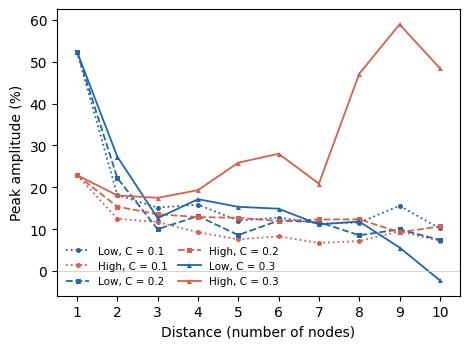

figure: figures_gamma\03\FIG_vFinal_A5_figure5_1graphe_pct.png


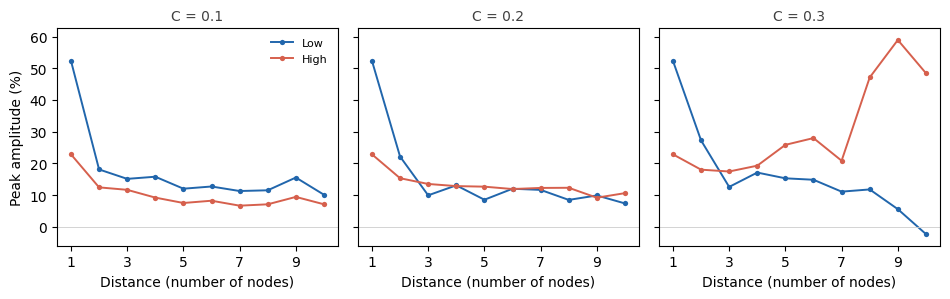

figure: figures_gamma\03\FIG_vFinal_A5_figure5_3graphes_pct.png


In [13]:
N_PRE_REL=N_PRE
def pic_causal_moyen_pct(nd, n_pre):
    m=np.asarray(nd["rs_m"], float)
    tt=(np.arange(len(m))-n_pre)*dt*1000
    pre=(tt>=-200)&(tt<-50)
    w=(tt>=0)&(tt<=150)
    b=float(m[pre].mean()) if np.any(pre) else float(nd["base_rs"])
    if not np.any(w):
        return float("nan")
    return float((m[w].max()-b)/max(abs(b), 1e-9)*100)

CACHE_REL=os.path.join(BASE, "propagation_relais_v6_cache.pkl")
PIC={}; BASES={}
if (not RECOMPUTE_FULL) and os.path.exists(CACHE_REL):
    with open(CACHE_REL, "rb") as f:
        saved=pickle.load(f)
    PIC=saved["PIC"]; BASES=saved["BASES"]
    print("cache relais v6")
else:
    n_use=N_STIM
    print("recalcul relais N=%d (cache v6)" % n_use, flush=True)
    for C in C_CHAIN_LIST:
        for lab in ("Low gamma", "High gamma"):
            print("  C=%.1f %s ..." % (C, lab), flush=True)
            nds=run_net_relais(STATES[lab]["Ele"], STATES[lab]["Eli"], C, n_use)
            PIC[(C, lab)]=np.array([pic_causal_moyen_pct(nd, N_PRE) for nd in nds])
            BASES[(C, lab)]=np.array([float(nd["base_rs"]) for nd in nds])
    with open(CACHE_REL, "wb") as f:
        pickle.dump({"PIC": PIC, "BASES": BASES}, f)

for C in C_CHAIN_LIST:
    for lab in ("Low gamma", "High gamma"):
        if (C, lab) in BASES:
            print("  baseline RS Hz  C=%.1f %s  %s" % (C, lab, np.array2string(BASES[(C, lab)], precision=2)))
if not PIC:
    print("aucune donnee relais pour tracer la figure")
else:
    x=np.arange(1,N_NODES_R+1)
    STYLE={0.1:":",0.2:"--",0.3:"-"}; MARK={0.1:"o",0.2:"s",0.3:"^"}
    COL={"Low gamma":C_LOW,"High gamma":C_HIGH}
    ymax=max(v.max() for v in PIC.values()); ymin=min(0.0,min(v.min() for v in PIC.values()))
    pad=0.06*(ymax-ymin); YL=(ymin-pad,ymax+pad)

    fig,ax=plt.subplots(figsize=(4.8,3.6))
    for C in C_CHAIN_LIST:
        for lab in ("Low gamma","High gamma"):
            if (C,lab) in PIC:
                ax.plot(x,PIC[(C,lab)],STYLE[C],color=COL[lab],marker=MARK[C],ms=3.6,lw=1.3,
                        mew=0.,label="%s, C = %g" % (lab.split()[0],C))
    ax.set_xlabel("Distance (number of nodes)")
    ax.set_ylabel("Peak amplitude (%)")
    ax.set_xticks(x); ax.set_xlim(0.5,N_NODES_R+0.5); ax.set_ylim(*YL)
    ax.axhline(0,color="0.8",lw=0.6); ax.grid(False)
    ax.legend(ncol=2,fontsize=7.5,frameon=False,handlelength=2.2,columnspacing=1.0)
    plt.tight_layout()
    fpath=os.path.join(FIGDIR,"FIG_vFinal_A5_figure5_1graphe_pct.png")
    plt.savefig(fpath,dpi=200,bbox_inches="tight"); plt.show(); print("figure: "+fpath)

    fig,axes=plt.subplots(1,3,figsize=(9.6,3.1),sharey=True)
    for j,C in enumerate(C_CHAIN_LIST):
        for lab in ("Low gamma","High gamma"):
            if (C,lab) in PIC:
                axes[j].plot(x,PIC[(C,lab)],"-",color=COL[lab],marker="o",ms=3.8,lw=1.4,
                             mew=0.,label=lab.split()[0])
        axes[j].set_title("C = %g" % C,fontsize=10,color="0.25")
        axes[j].set_xlabel("Distance (number of nodes)")
        axes[j].set_xticks(x[::2]); axes[j].set_xlim(0.5,N_NODES_R+0.5)
        axes[j].axhline(0,color="0.8",lw=0.6); axes[j].grid(False)
        if j==0:
            axes[j].set_ylabel("Peak amplitude (%)"); axes[j].set_ylim(*YL)
            axes[j].legend(fontsize=8,frameon=False)
    plt.tight_layout()
    fpath=os.path.join(FIGDIR,"FIG_vFinal_A5_figure5_3graphes_pct.png")
    plt.savefig(fpath,dpi=200,bbox_inches="tight"); plt.show(); print("figure: "+fpath)


In [14]:
_P_E_HUGO = np.array([-0.04829391053228397, 0.00015312526115162162,
                      -0.0018830942349703766, 0.0022357601238549274,
                      0.001287915223600697, -0.011256391905113705,
                      0.007827691831503352, 0.0010805275269078643,
                      -0.003810751044498102, 0.009008257129081343])
_P_I_HUGO = np.array([-0.05184978, 0.0061593, -0.01403522, 0.00166511,
                      -0.0020559, 0.00318432, -0.03112775, 0.00656668,
                      0.00171829, -0.04516385])
_ORDRE_FICHIER = [0, 1, 2, 3, 4, 7, 8, 5, 9, 6]

PRS = _P_E_HUGO[_ORDRE_FICHIER].copy()
PFS = _P_I_HUGO[_ORDRE_FICHIER].copy()


Coefficients de Hugo (controle contre mf_core_v4 fait le 27/10/2026 : ecart 5.7e-14 Hz, PASSE)
PRS (hugo) = [-0.048294  0.000153 -0.001883  0.002236  0.001288  0.001081 -0.003811
 -0.011256  0.009008  0.007828]
PFS (hugo) = [-0.05185   0.006159 -0.014035  0.001665 -0.002056  0.006567  0.001718
  0.003184 -0.045164 -0.031128]


In [15]:
def run_net_relais_bd(Ele_n, Eli_n, C_CHAIN, n_stim, seed=SEED, bidir=False, stim_node=0):
    T_ST=make_stim_rand(n_stim); T_TOT=float(T_ST[-1]+1.5); NST=int(T_TOT/dt)
    t_loc=np.arange(NST)*dt
    imp_net=np.zeros(NST)
    for ts in T_ST:
        imp_net+=AMP*np.exp(-0.5*((t_loc-ts)/0.010)**2)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    hist=max(DELAY_R, tau_e_d, tau_i_d)
    fe=np.ones((N_NODES_R, NST)); fi=np.ones((N_NODES_R, NST))
    ww=np.full((N_NODES_R, NST), 1e-10)
    xf=np.zeros((N_NODES_R, NST))
    for k in range(N_NODES_R):
        np.random.seed(int(seed)+k)
        _, xk=ornstein_uhlenbeck(mu, sigma, theta, dt, T_TOT, x0)
        xf[k]=xk[:-1]
    for step in range(hist, NST):
        for k in range(N_NODES_R):
            up=C_CHAIN*fe[k-1, step-DELAY_R] if k>0 else 0.0
            if bidir and k<N_NODES_R-1:
                up+=C_CHAIN*fe[k+1, step-DELAY_R]
            drive=xf[k, step]+input_to_exc+up+(imp_net[step] if k==stim_node else 0.0)
            fe_old=fe[k, step-1]; fi_old=fi[k, step-1]; w_old=ww[k, step-1]
            fe_new=fe_old+dt/T*(TF4(PRS, fe[k, step-tau_e_d]+drive, fi[k, step-tau_i_d], w_old, Ele_n, pconnec, pconnec)-fe_old)
            fi_new=fi_old+dt/T*(TF4(PFS, fe[k, step-tau_i_d]+drive, fi[k, step-tau_e_d], 0., Eli_n, pconnec, pconnec)-fi_old)
            w_new=w_old+dt*MFw4(fe_old, fi_old, w_old, fe_old, Ele_n, pconnec, pconnec)
            fe[k, step]=min(max(fe_new, 1e-9), 196.)
            fi[k, step]=min(max(fi_new, 1e-9), 196.)
            ww[k, step]=w_new
    out=[]
    for k in range(N_NODES_R):
        wins=[fe[k, int(round(ts/dt))-N_PRE:int(round(ts/dt))+N_POST] for ts in T_ST
              if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=NST]
        wins=np.asarray(wins, float)
        m=wins.mean(axis=0)
        out.append(dict(rs_m=m, base_rs=float(m[pre_sl].mean())))
    return out

In [16]:
C_LIST_BD=[0.01,0.05,0.1,0.2,0.3,0.4,0.5,1.0]

CONDITIONS_BD=[("bidir",0,C) for C in (0.1,0.2)]                     
CONDITIONS_BD+=[("bidir",0,C) for C in C_LIST_BD if C not in (0.1,0.2)]
CONDITIONS_BD+=[("bidir",5,C) for C in C_LIST_BD]
CONDITIONS_BD+=[("ff",5,C) for C in C_LIST_BD]
CONDITIONS_BD+=[("ff",0,C) for C in C_LIST_BD]   

N_CONDITIONS_A_CALCULER=len(CONDITIONS_BD)   

CACHE_BD=os.path.join(BASE, "propagation_relais_bidir_HUGO_cache.pkl")
PIC_BD={}; BASES_BD={}
if (not RECOMPUTE_FULL) and os.path.exists(CACHE_BD):
    with open(CACHE_BD, "rb") as f:
        saved=pickle.load(f)
    PIC_BD=saved["PIC"]; BASES_BD=saved["BASES"]
print("deja en cache : %d simulations" % len(PIC_BD))


import ctypes
from joblib import Parallel, delayed

def _go_libres():
    try:                                   # Windows
        class M(ctypes.Structure):
            _fields_ = [("l", ctypes.c_ulong), ("p", ctypes.c_ulong), ("t", ctypes.c_ulonglong),
                        ("a", ctypes.c_ulonglong), ("tp", ctypes.c_ulonglong), ("ap", ctypes.c_ulonglong),
                        ("tv", ctypes.c_ulonglong), ("av", ctypes.c_ulonglong), ("e", ctypes.c_ulonglong)]
        m = M(); m.l = ctypes.sizeof(M)
        ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(m))
        return m.a / 1e9
    except Exception:
        try:                               # Linux / Mac
            for l in open("/proc/meminfo"):
                if l.startswith("MemAvailable"):
                    return int(l.split()[1]) / 1e6
        except Exception:
            pass
    return 6.0

N_PROC = max(1, min(8, (os.cpu_count() or 2) - 1, int(_go_libres() - 2)))   

def _une_simulation(geom, stim, C, lab):
    nds=run_net_relais_bd(STATES[lab]["Ele"], STATES[lab]["Eli"], C, N_STIM,
                          bidir=(geom=="bidir"), stim_node=stim)
    return ((geom, stim, C, lab),
            np.array([pic_causal_moyen_pct(nd, N_PRE) for nd in nds]),
            np.array([float(nd["base_rs"]) for nd in nds]))

a_faire=[(geom, stim, C, lab) for (geom, stim, C) in CONDITIONS_BD[:N_CONDITIONS_A_CALCULER]
         for lab in ("Low gamma", "High gamma") if (geom, stim, C, lab) not in PIC_BD]
print("a calculer : %d simulations, %d en parallele" % (len(a_faire), N_PROC), flush=True)

t0=time.time()
for i in range(0, len(a_faire), N_PROC):
    lot=a_faire[i:i+N_PROC]
    for cle, pic, base in Parallel(n_jobs=N_PROC)(delayed(_une_simulation)(*k) for k in lot):
        PIC_BD[cle]=pic; BASES_BD[cle]=base
        print("  %-5s  stim noeud %d  C=%-4g  %s" % cle, flush=True)
    with open(CACHE_BD, "wb") as f:
        pickle.dump({"PIC": PIC_BD, "BASES": BASES_BD}, f)
    print("  -> %d / %d faites, %.0f min ecoulees" % (min(i+N_PROC, len(a_faire)), len(a_faire),
                                                       (time.time()-t0)/60.), flush=True)


for key in sorted(BASES_BD, key=lambda k: (k[0], k[1], k[2], k[3])):
    print("  baseline RS Hz  %-5s stim %d  C=%-4g %-10s %s"
          % (key[0], key[1], key[2], key[3], np.array2string(BASES_BD[key], precision=2)))

deja en cache : 64 simulations


a calculer : 0 simulations, 1 en parallele


  baseline RS Hz  bidir stim 0  C=0.01 High gamma [6.61 6.64 6.6  6.63 6.65 6.66 6.59 6.64 6.61 6.62]
  baseline RS Hz  bidir stim 0  C=0.01 Low gamma  [1.82 1.83 1.83 1.82 1.8  1.83 1.8  1.85 1.83 1.84]
  baseline RS Hz  bidir stim 0  C=0.05 High gamma [6.8  6.94 6.97 6.96 6.9  6.98 6.91 6.96 6.98 6.79]
  baseline RS Hz  bidir stim 0  C=0.05 Low gamma  [1.89 1.96 1.99 1.99 1.92 1.96 1.96 2.02 2.   1.92]
  baseline RS Hz  bidir stim 0  C=0.1  High gamma [7.14 7.68 7.75 7.67 7.57 7.63 7.65 7.59 7.61 7.15]
  baseline RS Hz  bidir stim 0  C=0.1  Low gamma  [2.08 2.31 2.33 2.35 2.36 2.37 2.37 2.4  2.35 2.09]
  baseline RS Hz  bidir stim 0  C=0.2  High gamma [11.54 16.61 18.84 19.71 20.04 19.92 19.63 18.65 16.42 11.28]
  baseline RS Hz  bidir stim 0  C=0.2  Low gamma  [2.69 3.38 3.65 3.73 3.79 3.83 3.79 3.66 3.4  2.68]
  baseline RS Hz  bidir stim 0  C=0.3  High gamma [178.42 193.63 193.75 193.75 193.75 193.75 193.75 193.75 193.63 178.48]
  baseline RS Hz  bidir stim 0  C=0.3  Low gamma  [ 

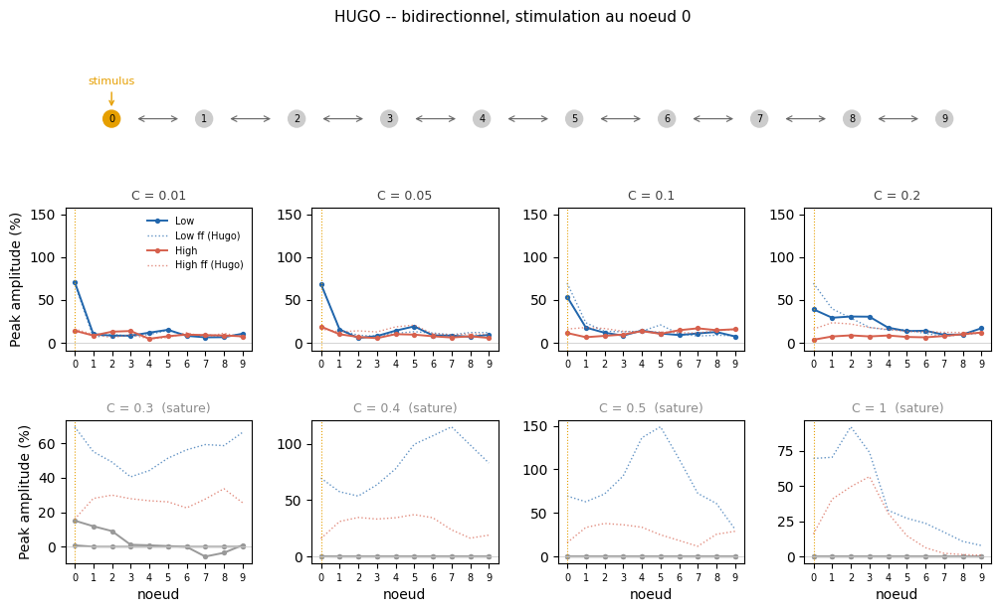

figure: figures_gamma\03\FIG_propagation_HUGO_bidir_stim0.png


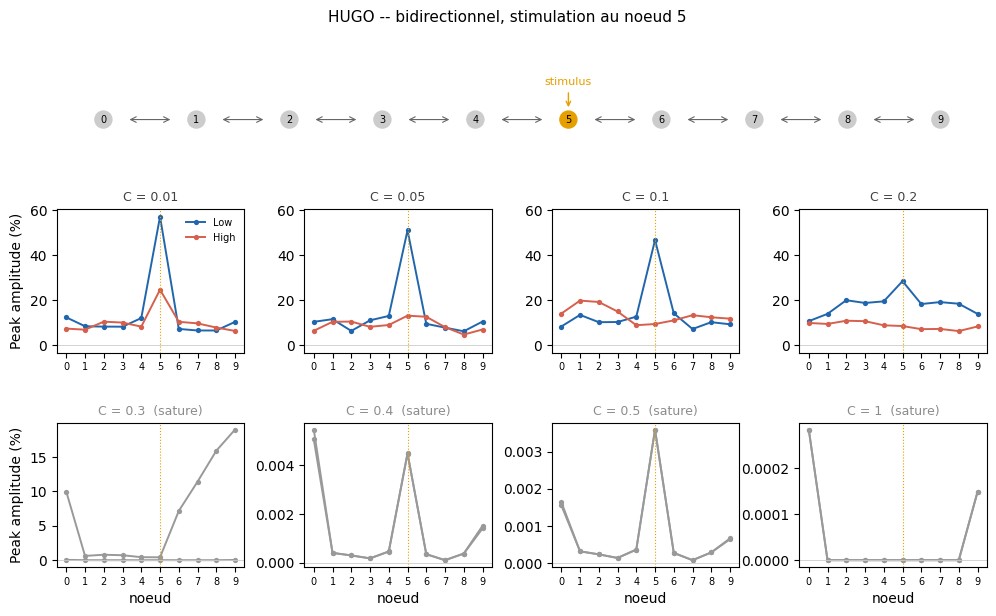

figure: figures_gamma\03\FIG_propagation_HUGO_bidir_stim5.png


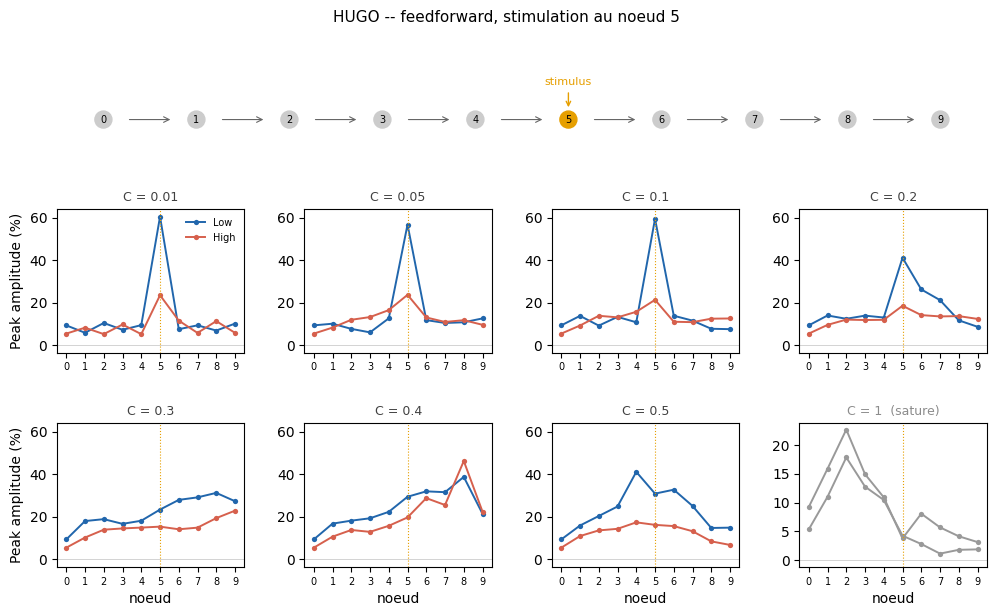

figure: figures_gamma\03\FIG_propagation_HUGO_ff_stim5.png


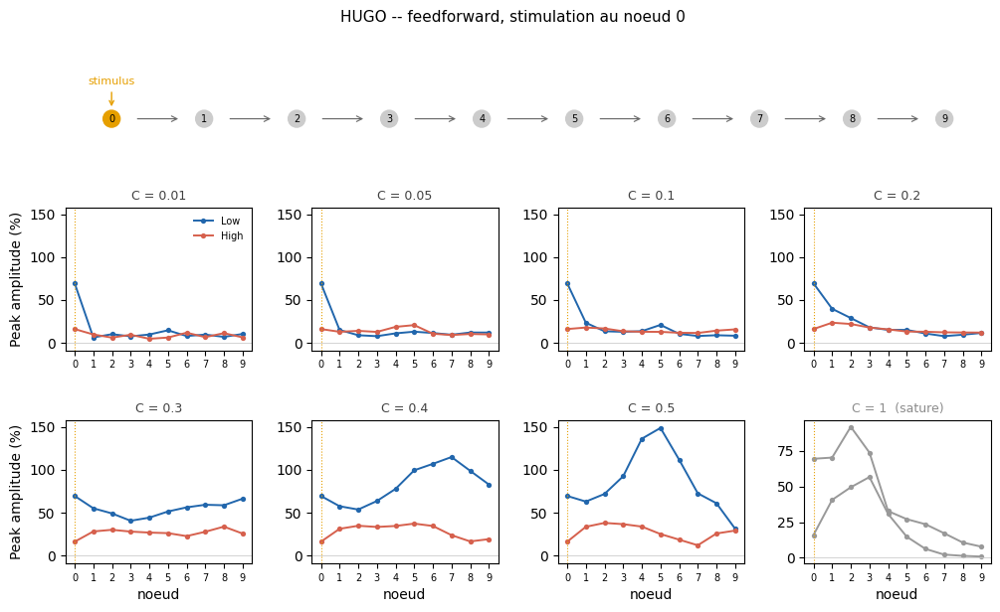

figure: figures_gamma\03\FIG_propagation_HUGO_ff_stim0.png
C=0.1  Low gamma  ff    stim 0 : [69.5 23.3 13.4 12.7 13.5]
C=0.1  Low gamma  bidir stim 0 : [53.6 17.7 11.7  8.3 14.3]
C=0.1  High gamma ff    stim 0 : [16.  17.7 16.6 13.4 12.8]
C=0.1  High gamma bidir stim 0 : [11.4  6.5  8.   9.5 13.5]
C=0.2  Low gamma  ff    stim 0 : [69.5 39.6 28.8 17.9 15. ]
C=0.2  Low gamma  bidir stim 0 : [39.  29.2 30.6 30.4 17.6]
C=0.2  High gamma ff    stim 0 : [16.  23.4 21.9 17.8 15.6]
C=0.2  High gamma bidir stim 0 : [3.5 7.3 8.6 7.4 8.4]


In [17]:
COL={"Low gamma":C_LOW, "High gamma":C_HIGH}
x=np.arange(1, N_NODES_R+1)          
SATURE=150.                          
NOMS={"bidir":"bidirectionnel", "ff":"feedforward"}

def schema(ax, geom, stim):
    cols=["#E69F00" if k==stim else "0.8" for k in range(N_NODES_R)]
    ax.scatter(x, np.zeros(N_NODES_R), s=150, c=cols, zorder=3)
    for k in range(N_NODES_R):
        ax.text(x[k], 0, str(k), ha="center", va="center", fontsize=7, zorder=4)
    for k in range(N_NODES_R-1):
        ax.annotate("", xy=(x[k]+0.75, 0), xytext=(x[k]+0.25, 0),
                    arrowprops=dict(arrowstyle=("<->" if geom=="bidir" else "->"), lw=0.8, color="0.4"))
    ax.annotate("stimulus", xy=(x[stim], 0.25), xytext=(x[stim], 0.9), ha="center", fontsize=8,
                color="#E69F00", arrowprops=dict(arrowstyle="->", lw=1.0, color="#E69F00"))
    ax.set_xlim(0.5, N_NODES_R+0.5); ax.set_ylim(-0.5, 1.2); ax.axis("off")

for (geom, stim) in [("bidir",0), ("bidir",5), ("ff",5), ("ff",0)]:
    cles=[(C, lab) for C in C_LIST_BD for lab in COL if (geom, stim, C, lab) in PIC_BD]
    if not cles:
        print("%s, stimulation au noeud %d : rien a tracer pour l'instant" % (NOMS[geom], stim))
        continue
    sature={C: any(BASES_BD[(geom, stim, C, lab)].max()>SATURE
                   for lab in COL if (geom, stim, C, lab) in BASES_BD) for C in C_LIST_BD}
    vals=[PIC_BD[(geom, stim, C, lab)] for (C, lab) in cles if not sature[C]]
    if geom=="bidir" and stim==0:
        vals+=[PIC_BD[("ff", 0, CC, ll)] for CC in C_LIST_BD for ll in COL if ("ff", 0, CC, ll) in PIC_BD]
    if vals:
        ymax=max(v.max() for v in vals); ymin=min(0.0, min(v.min() for v in vals))
        pad=0.06*(ymax-ymin); YL=(ymin-pad, ymax+pad)
    else:
        YL=None

    fig=plt.figure(figsize=(12, 6.4))
    gs=gridspec.GridSpec(3, 4, height_ratios=[0.45, 1, 1], hspace=0.6, wspace=0.32)
    schema(fig.add_subplot(gs[0, :]), geom, stim)
    for j, C in enumerate(C_LIST_BD):
        ax=fig.add_subplot(gs[1+j//4, j%4])
        if not any((geom, stim, C, lab) in PIC_BD for lab in COL):
            ax.text(0.5, 0.5, "pas encore calcule", transform=ax.transAxes,
                    ha="center", va="center", fontsize=8, color="0.6")
        for lab in COL:
            if (geom, stim, C, lab) in PIC_BD:
                ax.plot(x, PIC_BD[(geom, stim, C, lab)], "-", color=(COL[lab] if not sature[C] else "0.6"),
                        marker="o", ms=3.8, lw=1.4, mew=0., label=lab.split()[0])
            if geom=="bidir" and stim==0 and ("ff", 0, C, lab) in PIC_BD:
                ax.plot(x, PIC_BD[("ff", 0, C, lab)], ":", color=COL[lab], lw=1.0, alpha=0.7,
                        label=lab.split()[0]+" ff (Hugo)")
        ax.axvline(x[stim], color="#E69F00", lw=0.8, ls=":")
        ax.axhline(0, color="0.8", lw=0.6)
        ax.set_title("C = %g%s" % (C, "  (sature)" if sature[C] else ""), fontsize=9,
                     color=("0.55" if sature[C] else "0.25"))
        ax.set_xticks(x); ax.set_xticklabels([str(k) for k in range(N_NODES_R)], fontsize=7)
        ax.set_xlim(0.5, N_NODES_R+0.5)
        if YL is not None and not sature[C]:
            ax.set_ylim(*YL)
        if j%4==0:
            ax.set_ylabel("Peak amplitude (%)")
        if j>=4:
            ax.set_xlabel("noeud")
        if j==0:
            ax.legend(fontsize=7, frameon=False)
    fig.suptitle("HUGO -- %s, stimulation au noeud %d" % (NOMS[geom], stim), fontsize=11)
    fpath=os.path.join(FIGDIR, "FIG_propagation_HUGO_%s_stim%d.png" % (geom, stim))
    plt.savefig(fpath, dpi=200, bbox_inches="tight"); plt.show(); print("figure: "+fpath)

for C in (0.1, 0.2):
    for lab in COL:
        for geom in ("ff", "bidir"):
            if (geom, 0, C, lab) in PIC_BD:
                print("C=%-4g %-10s %-5s stim 0 : %s" % (C, lab, geom,
                      np.array2string(PIC_BD[(geom, 0, C, lab)][:5], precision=1)))

In [18]:
def run_net_relais_ctl(Ele_n, Eli_n, C_CHAIN, n_stim, seed=SEED, bidir=False, stim_node=0):
    T_ST=make_stim_rand(n_stim); T_TOT=float(T_ST[-1]+1.5); NST=int(T_TOT/dt)
    t_loc=np.arange(NST)*dt
    imp_net=np.zeros(NST)
    for ts in T_ST:
        imp_net+=AMP*np.exp(-0.5*((t_loc-ts)/0.010)**2)
    tau_e_d=int((1+epsilon)*tau_l/dt); tau_i_d=int((1-epsilon)*tau_l/dt)
    hist=max(DELAY_R, tau_e_d, tau_i_d)
    xf=np.zeros((N_NODES_R, NST))
    for k in range(N_NODES_R):
        np.random.seed(int(seed)+k)
        _, xk=ornstein_uhlenbeck(mu, sigma, theta, dt, T_TOT, x0)
        xf[k]=xk[:-1]

    def boucle(imp):
        fe=np.ones((N_NODES_R, NST)); fi=np.ones((N_NODES_R, NST))
        ww=np.full((N_NODES_R, NST), 1e-10)
        for step in range(hist, NST):
            for k in range(N_NODES_R):
                up=C_CHAIN*fe[k-1, step-DELAY_R] if k>0 else 0.0
                if bidir and k<N_NODES_R-1:
                    up+=C_CHAIN*fe[k+1, step-DELAY_R]
                drive=xf[k, step]+input_to_exc+up+(imp[step] if k==stim_node else 0.0)
                fe_old=fe[k, step-1]; fi_old=fi[k, step-1]; w_old=ww[k, step-1]
                fe_new=fe_old+dt/T*(TF4(PRS, fe[k, step-tau_e_d]+drive, fi[k, step-tau_i_d], w_old, Ele_n, pconnec, pconnec)-fe_old)
                fi_new=fi_old+dt/T*(TF4(PFS, fe[k, step-tau_i_d]+drive, fi[k, step-tau_e_d], 0., Eli_n, pconnec, pconnec)-fi_old)
                w_new=w_old+dt*MFw4(fe_old, fi_old, w_old, fe_old, Ele_n, pconnec, pconnec)
                fe[k, step]=min(max(fe_new, 1e-9), 196.)
                fi[k, step]=min(max(fi_new, 1e-9), 196.)
                ww[k, step]=w_new
        return fe

    fe_s=boucle(imp_net)               
    fe_c=boucle(np.zeros(NST))        
    idx=[int(round(ts/dt)) for ts in T_ST if int(round(ts/dt))-N_PRE>=0 and int(round(ts/dt))+N_POST<=NST]
    t_w=np.arange(-N_PRE, N_POST)*dt*1000
    fen=(t_w>=0)&(t_w<=150)
    out=[]
    for k in range(N_NODES_R):
        ws=np.array([fe_s[k, i-N_PRE:i+N_POST] for i in idx]); wc=np.array([fe_c[k, i-N_PRE:i+N_POST] for i in idx])
        m=ws.mean(axis=0); mc=wc.mean(axis=0); d=ws-wc; dm=d.mean(axis=0); dsem=d.std(axis=0, ddof=1)/np.sqrt(len(d))
        j=int(np.argmax(dm[fen]))
        out.append(dict(rs_m=m, base_rs=float(m[pre_sl].mean()), ctl_m=mc, base_ctl=float(mc[pre_sl].mean()),
                        d_m=dm.astype(np.float32), dpic_hz=float(dm[fen][j]), dpic_sem=float(dsem[fen][j])))
    return out

In [19]:
C_LIST_CTL=[0.01, 0.05, 0.1, 0.15, 0.2]
CAS_CTL=[("bidir",0), ("bidir",5), ("ff",5), ("ff",0)]
CACHE_CTL=os.path.join(BASE, "propagation_relais_ctrl_HUGO_cache.pkl")
PREFIXE_FIG="FIG_HUGO_CTRL_"
TITRE_CTL="HUGO -- "
RES_CTL=pickle.load(open(CACHE_CTL, "rb")) if os.path.exists(CACHE_CTL) else {}

def _une_ctl(geom, stim, C, lab):
    nds=run_net_relais_ctl(STATES[lab]["Ele"], STATES[lab]["Eli"], C, N_STIM, bidir=(geom=="bidir"), stim_node=stim)
    r=dict(pic=np.array([pic_causal_moyen_pct(nd, N_PRE) for nd in nds]),
           plancher=np.array([pic_causal_moyen_pct(dict(rs_m=nd["ctl_m"], base_rs=nd["base_ctl"]), N_PRE) for nd in nds]),
           base=np.array([nd["base_rs"] for nd in nds]),
           dpic_hz=np.array([nd["dpic_hz"] for nd in nds]), dpic_sem=np.array([nd["dpic_sem"] for nd in nds]),
           d_m=np.array([nd["d_m"] for nd in nds]).T,
           rs_m=np.array([nd["rs_m"] for nd in nds]).T.astype(np.float32),
           ctl_m=np.array([nd["ctl_m"] for nd in nds]).T.astype(np.float32))
    return (geom, stim, C, lab), r

a_faire_ctl=[(g, s, C, lab) for (g, s) in CAS_CTL for C in C_LIST_CTL for lab in ("Low gamma", "High gamma")
             if (g, s, C, lab) not in RES_CTL]
N_PROC_CTL=max(1, min(8, (os.cpu_count() or 2)-1, int(_go_libres()-2)))
print("controle : deja %d, a calculer %d conditions (x2 simulations), %d en parallele" % (len(RES_CTL), len(a_faire_ctl), N_PROC_CTL), flush=True)
t0=time.time()
for i in range(0, len(a_faire_ctl), N_PROC_CTL):
    lot=a_faire_ctl[i:i+N_PROC_CTL]
    for cle, r in Parallel(n_jobs=N_PROC_CTL)(delayed(_une_ctl)(*k) for k in lot):
        RES_CTL[cle]=r
        print("  %-5s stim %d  C=%-4g %-10s  pic %.1f %% (plancher %.1f %%)"
              % (cle[0], cle[1], cle[2], cle[3], r["pic"][cle[1]], r["plancher"][cle[1]]), flush=True)
    with open(CACHE_CTL, "wb") as f:
        pickle.dump(RES_CTL, f)
    print("  -> %d / %d, %.0f min" % (min(i+N_PROC_CTL, len(a_faire_ctl)), len(a_faire_ctl), (time.time()-t0)/60.), flush=True)

controle : deja 40, a calculer 0 conditions (x2 simulations), 1 en parallele


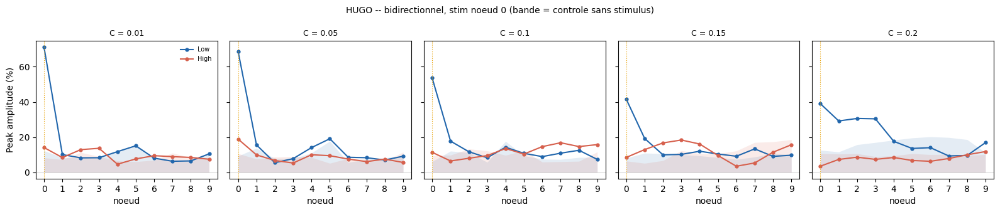

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_article_bidir_stim0.png


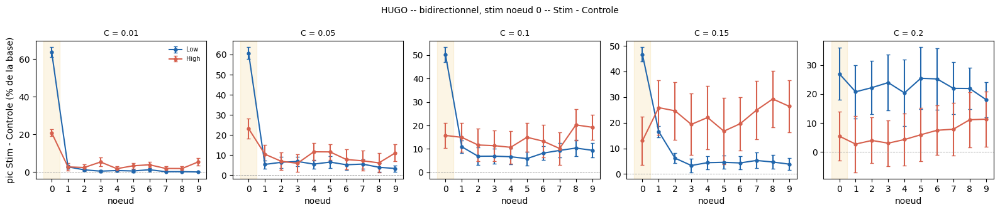

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_stim_moins_controle_bidir_stim0.png


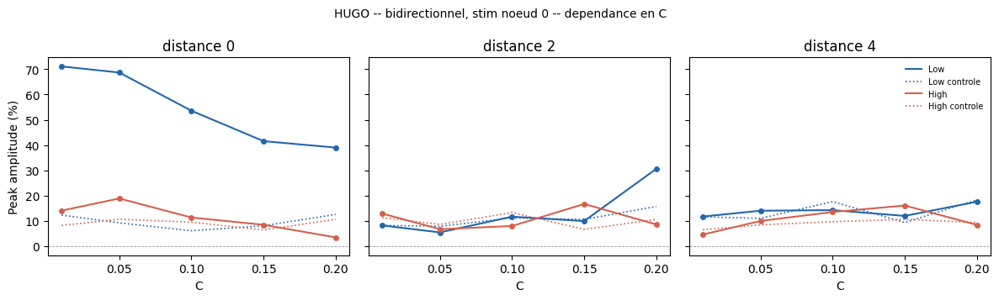

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_dependance_C_bidir_stim0.png


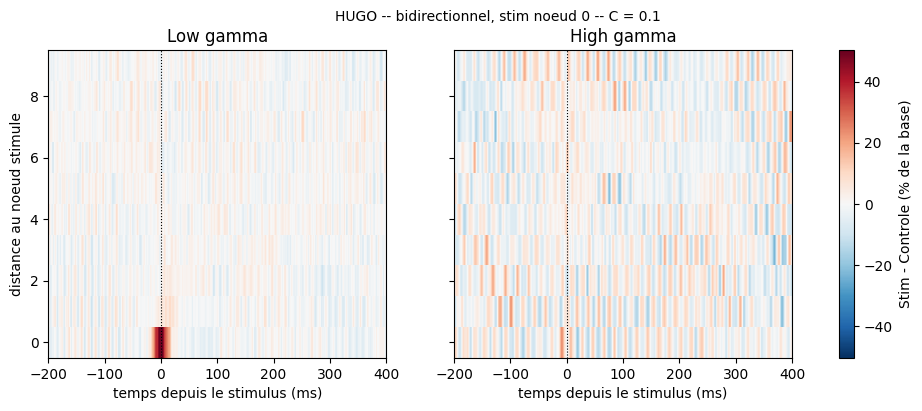

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_bidir_stim0_C0.1.png


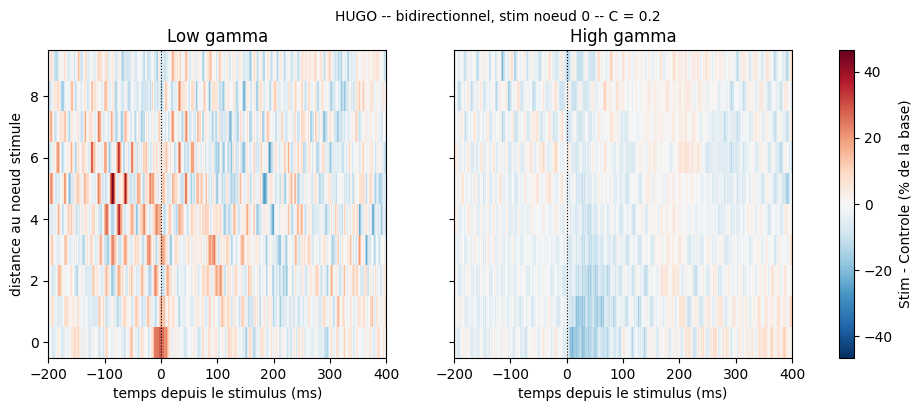

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_bidir_stim0_C0.2.png


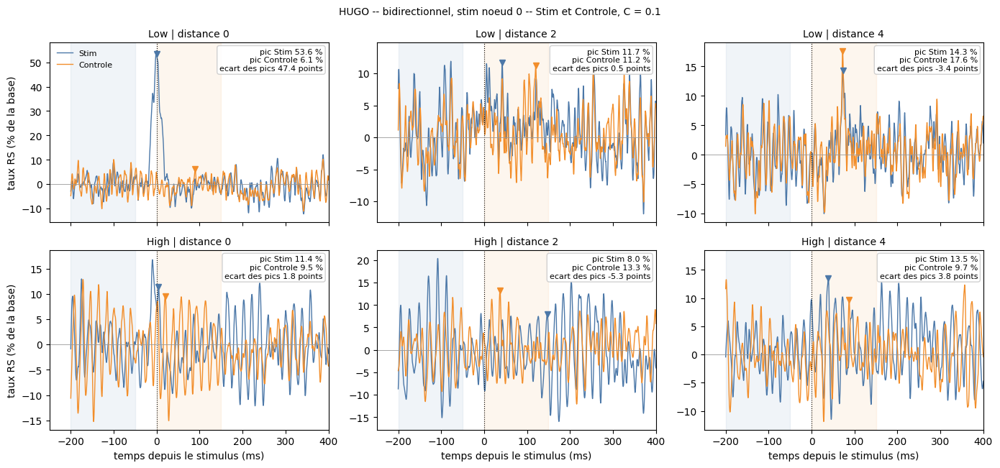

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_traces_bidir_stim0_C0.1.png


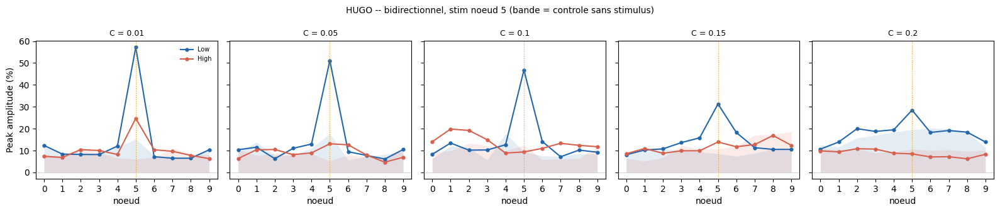

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_article_bidir_stim5.png


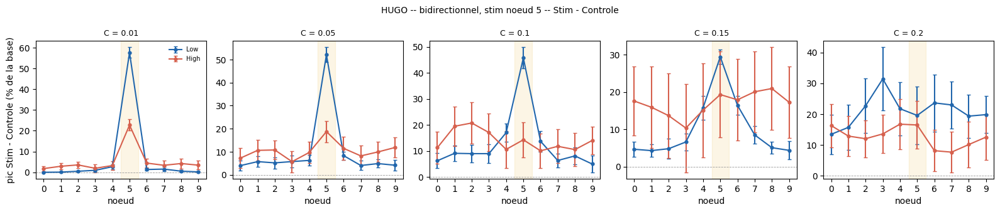

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_stim_moins_controle_bidir_stim5.png


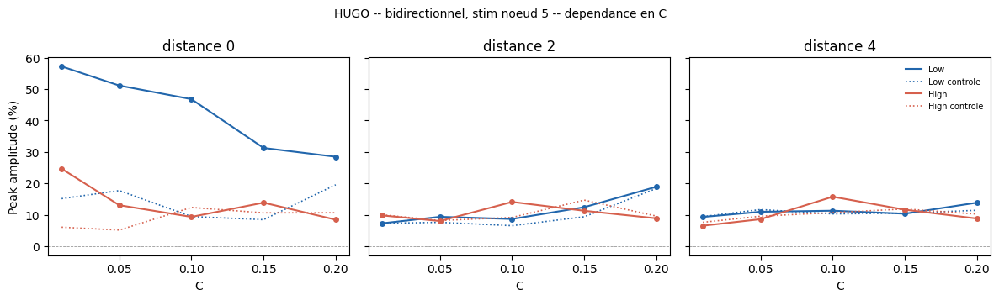

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_dependance_C_bidir_stim5.png


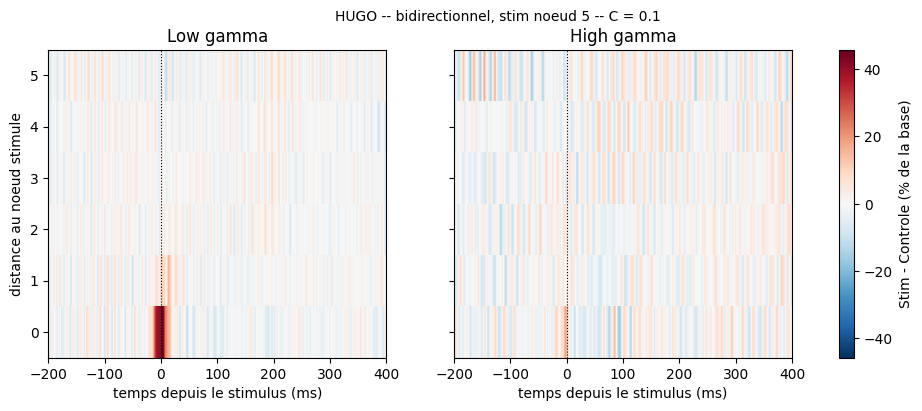

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_bidir_stim5_C0.1.png


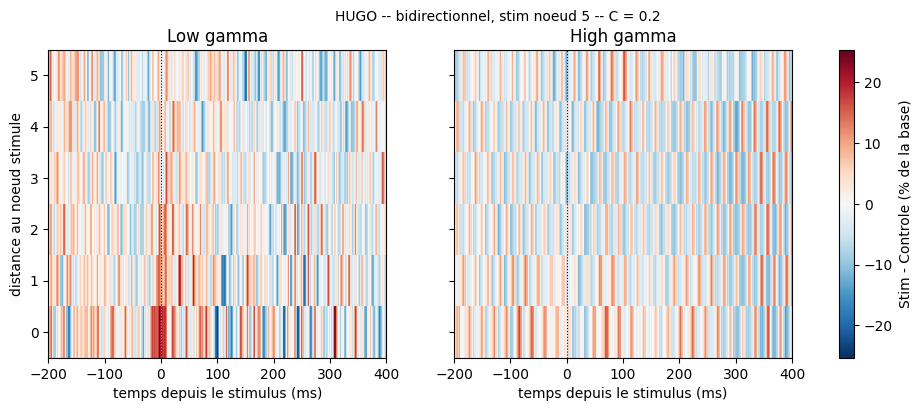

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_bidir_stim5_C0.2.png


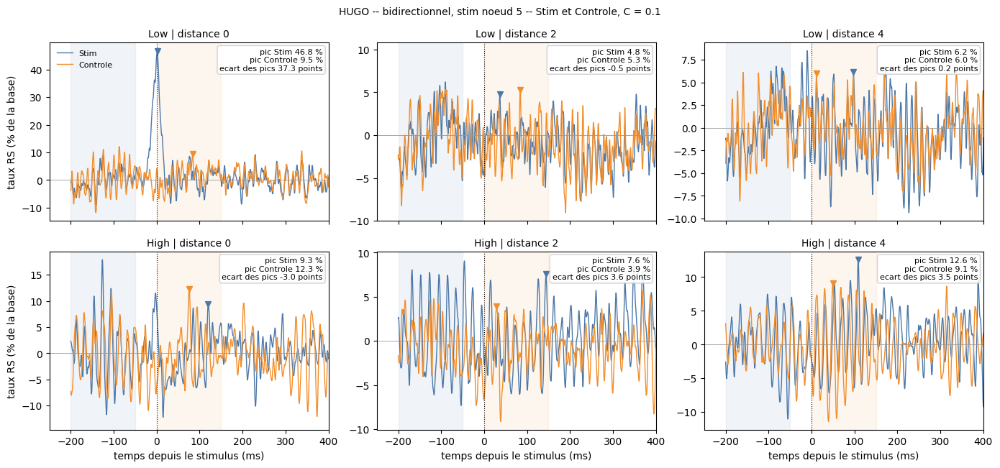

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_traces_bidir_stim5_C0.1.png


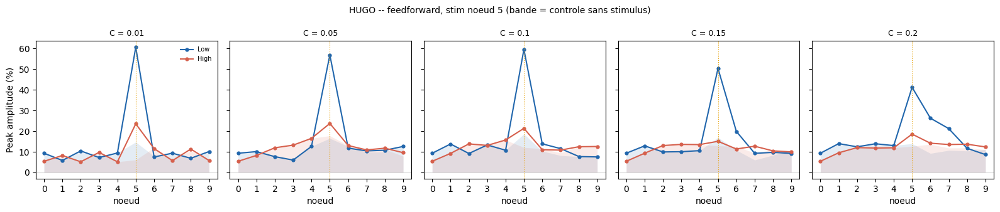

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_article_ff_stim5.png


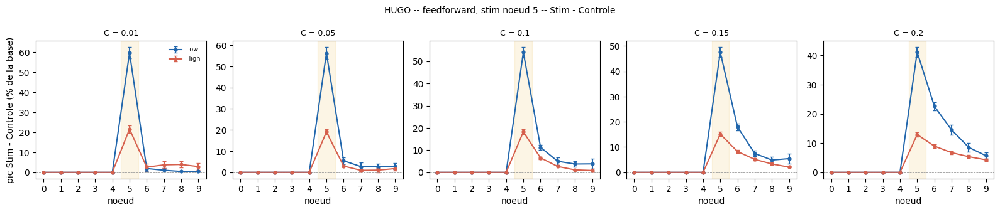

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_stim_moins_controle_ff_stim5.png


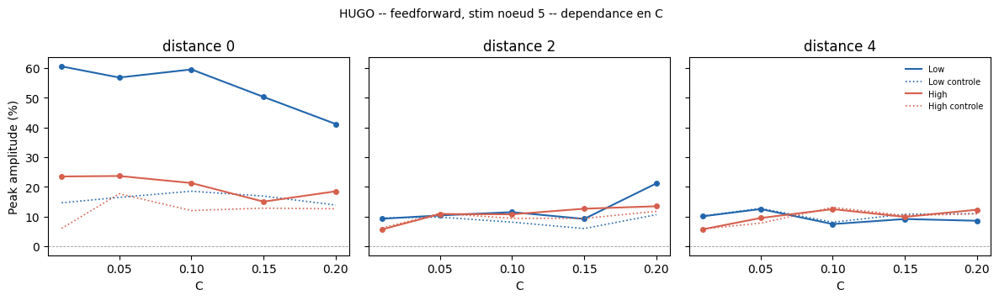

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_dependance_C_ff_stim5.png


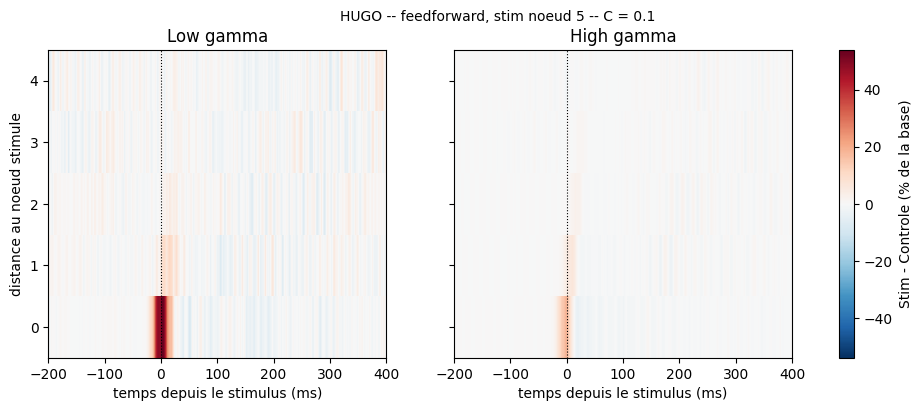

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_ff_stim5_C0.1.png


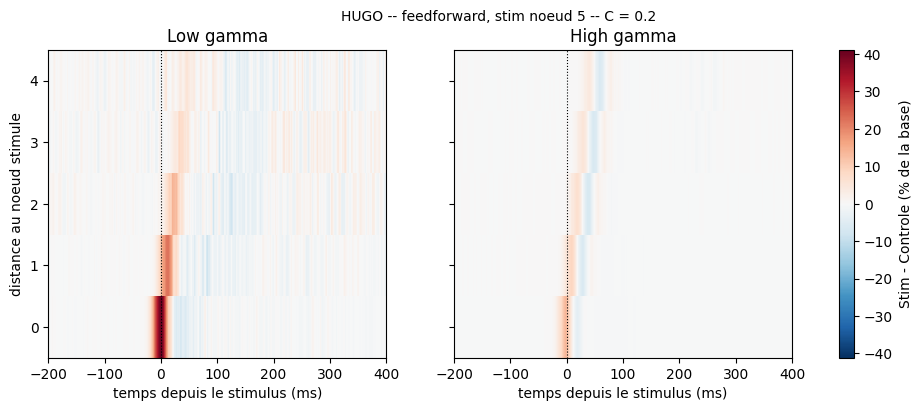

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_ff_stim5_C0.2.png


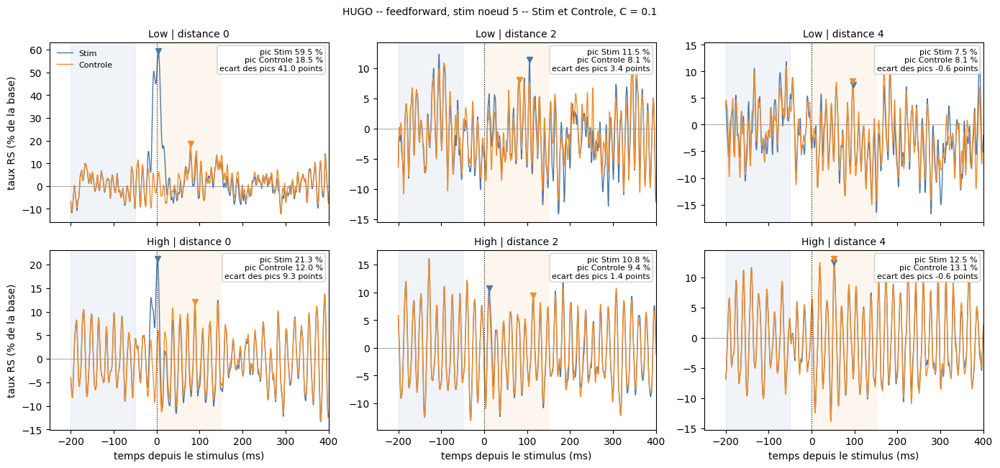

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_traces_ff_stim5_C0.1.png


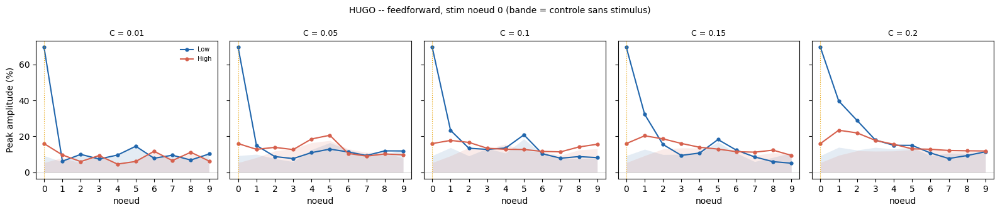

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_article_ff_stim0.png


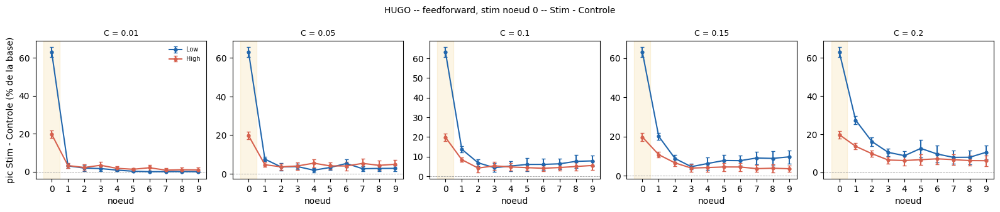

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_stim_moins_controle_ff_stim0.png


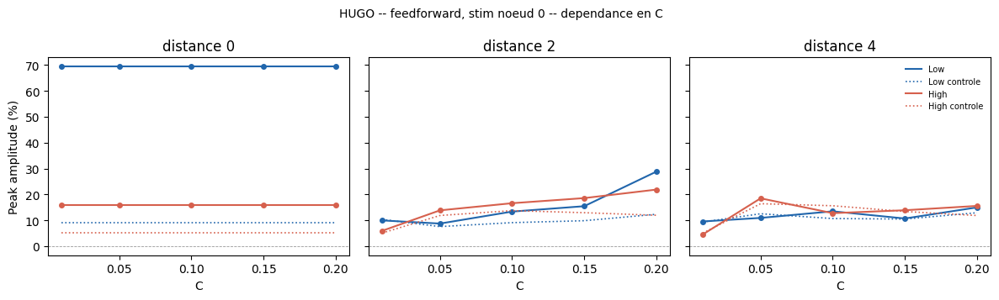

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_dependance_C_ff_stim0.png


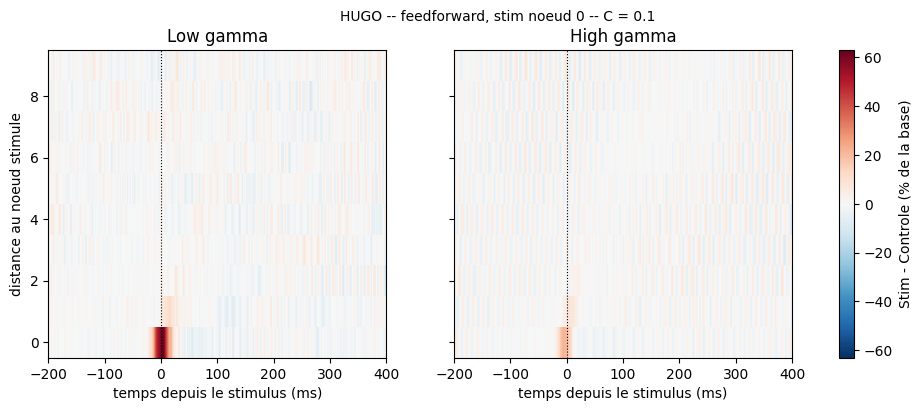

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_ff_stim0_C0.1.png


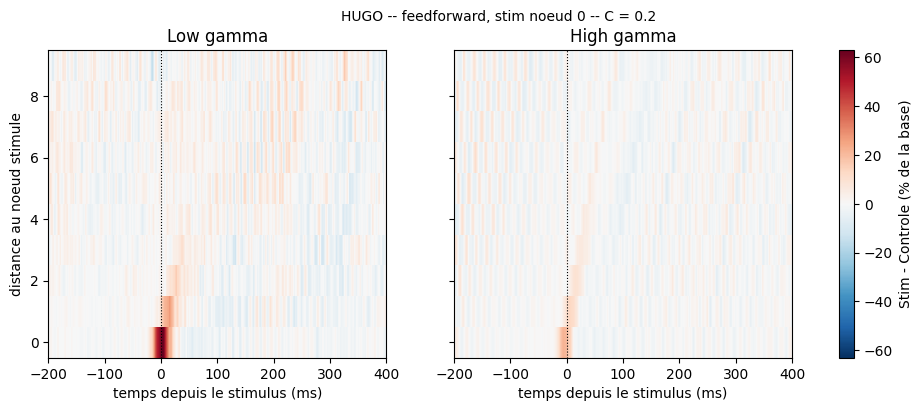

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_temps_distance_ff_stim0_C0.2.png


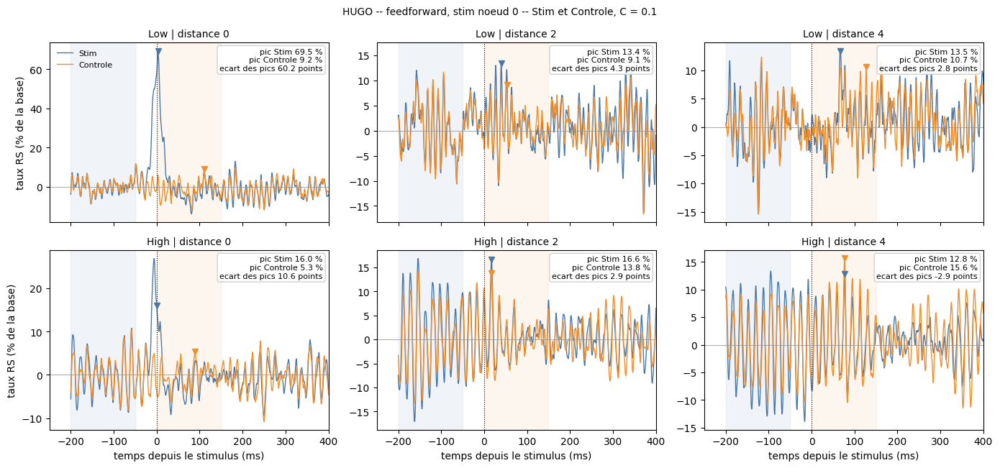

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_traces_ff_stim0_C0.1.png

HUGO -- bidirectionnel, stim noeud 0
   C     etat        d=0 Stim | Ctl     d=2 Stim | Ctl     d=4 Stim | Ctl
  0.01  Low gamma     71.1 |  12.3       8.2 |   8.3      11.8 |  11.7
  0.01  High gamma    14.1 |   8.3      12.9 |  11.3       4.6 |   6.5
  0.05  Low gamma     68.7 |   9.3       5.5 |   7.9      14.0 |  11.0
  0.05  High gamma    18.9 |  10.7       6.7 |   8.7      10.0 |   8.5
  0.1   Low gamma     53.6 |   6.1      11.7 |  11.2      14.3 |  17.6
  0.1   High gamma    11.4 |   9.5       8.0 |  13.3      13.5 |   9.7
  0.15  Low gamma     41.6 |   8.1       9.9 |  10.6      12.0 |   9.4
  0.15  High gamma     8.5 |   6.4      16.7 |   6.7      16.1 |  10.6
  0.2   Low gamma     39.0 |  12.6      30.6 |  15.7      17.6 |  18.3
  0.2   High gamma     3.5 |  10.7       8.6 |  10.6       8.4 |   9.4

HUGO -- bidirectionnel, stim noeud 5
   C     etat        d=0 Stim | Ctl     d=2 Stim | Ctl     d=4 Stim | Ct

In [20]:
COL={"Low gamma":C_LOW, "High gamma":C_HIGH}
NOMS={"bidir":"bidirectionnel", "ff":"feedforward"}
PRE_MS, FEN_MS = (-200, -50), (0, 150)      
SATURE = 150.                                
C_TRACE = 0.1

def profil(v, geom, stim):
    dist=(np.arange(N_NODES_R)-stim).astype(float)
    if geom=="ff":
        dist[dist<0]=np.nan
    else:
        dist=np.abs(dist)
    ud=np.unique(dist[~np.isnan(dist)])
    v=np.asarray(v)
    if v.ndim>1:
        return ud, np.array([v[:, dist==u].mean(axis=1) for u in ud]).T
    return ud, np.array([v[dist==u].mean() for u in ud])

def temps(r):
    return np.arange(r["rs_m"].shape[0])*dt*1000 - N_PRE*dt*1000

def masques(t):
    return (t>=PRE_MS[0])&(t<PRE_MS[1]), (t>=FEN_MS[0])&(t<=FEN_MS[1])

def en_pct(y, t):
    pre, _=masques(t); b=y[pre].mean(0)
    return (y-b)/np.maximum(np.abs(b), 1e-9)*100

def stim_moins_ctl_pct(r):
    t=temps(r); pre, fen=masques(t)
    bc=np.maximum(np.abs(r["ctl_m"][pre].mean(0)), 1e-9)
    return r["d_m"]/bc*100, r["d_m"][fen].max(0)/bc*100, r["dpic_sem"]/bc*100

def sature(r):
    return r["base"].max()>SATURE

def _sauve(fig, nom):
    fp=os.path.join(FIGDIR, PREFIXE_FIG+"PCT_"+nom+".png")
    fig.savefig(fp, dpi=150, bbox_inches="tight"); plt.show(); print("figure: "+fp)

for (geom, stim) in CAS_CTL:
    if not any((geom, stim, C, l) in RES_CTL for C in C_LIST_CTL for l in COL):
        continue
    fig, axs=plt.subplots(1, len(C_LIST_CTL), figsize=(3.2*len(C_LIST_CTL), 3.4), sharey=True, squeeze=False); axs=axs[0]
    for ax, C in zip(axs, C_LIST_CTL):
        for lab in COL:
            if (geom, stim, C, lab) in RES_CTL:
                r=RES_CTL[(geom, stim, C, lab)]
                ax.fill_between(range(N_NODES_R), 0, r["plancher"], color=COL[lab], alpha=0.12, lw=0)
                ax.plot(range(N_NODES_R), r["pic"], "-o", ms=3.5, color=(COL[lab] if not sature(r) else "0.6"), label=lab.split()[0])
        ax.axvline(stim, color="#E69F00", ls=":", lw=0.8); ax.axhline(0, color="0.8", lw=0.6)
        ax.set_title("C = %g" % C, fontsize=9); ax.set_xticks(range(N_NODES_R)); ax.set_xlabel("noeud")
    axs[0].set_ylabel("Peak amplitude (%)"); axs[0].legend(fontsize=7, frameon=False)
    fig.suptitle("%s%s, stim noeud %d (bande = controle sans stimulus)" % (TITRE_CTL, NOMS[geom], stim), fontsize=10)
    plt.tight_layout(); _sauve(fig, "article_%s_stim%d" % (geom, stim))

    fig, axs=plt.subplots(1, len(C_LIST_CTL), figsize=(3.2*len(C_LIST_CTL), 3.4), squeeze=False); axs=axs[0]
    for ax, C in zip(axs, C_LIST_CTL):
        for lab in COL:
            if (geom, stim, C, lab) in RES_CTL:
                r=RES_CTL[(geom, stim, C, lab)]
                _, y, e=stim_moins_ctl_pct(r)
                ax.errorbar(range(N_NODES_R), y, yerr=e, fmt="-o", ms=3.5, capsize=2, color=(COL[lab] if not sature(r) else "0.6"), label=lab.split()[0])
        ax.axvspan(stim-0.5, stim+0.5, color="#E69F00", alpha=0.10); ax.axhline(0, color="0.6", lw=0.6, ls="--")
        ax.set_title("C = %g" % C, fontsize=9); ax.set_xticks(range(N_NODES_R)); ax.set_xlabel("noeud")
    axs[0].set_ylabel("pic Stim - Controle (% de la base)"); axs[0].legend(fontsize=7, frameon=False)
    fig.suptitle("%s%s, stim noeud %d -- Stim - Controle" % (TITRE_CTL, NOMS[geom], stim), fontsize=10)
    plt.tight_layout(); _sauve(fig, "stim_moins_controle_%s_stim%d" % (geom, stim))

    fig, axs=plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    for ax, dd in zip(axs, (0, 2, 4)):
        for lab in COL:
            xs, ys, fs, ss=[], [], [], []
            for C in C_LIST_CTL:
                if (geom, stim, C, lab) in RES_CTL:
                    r=RES_CTL[(geom, stim, C, lab)]
                    ud, y=profil(r["pic"], geom, stim); _, f=profil(r["plancher"], geom, stim)
                    if dd in ud:
                        j=list(ud).index(dd); xs.append(C); ys.append(y[j]); fs.append(f[j]); ss.append(sature(r))
            if xs:
                xs, ys, fs, ss=map(np.array, (xs, ys, fs, ss))
                ax.plot(xs, ys, "-", color=COL[lab], label=lab.split()[0])
                ax.plot(xs[~ss], ys[~ss], "o", ms=4, color=COL[lab]); ax.plot(xs[ss], ys[ss], "x", ms=6, color="0.5")
                ax.plot(xs, fs, ":", lw=1.2, color=COL[lab], label=lab.split()[0]+" controle")
        ax.axhline(0, color="0.6", lw=0.6, ls="--"); ax.set_title("distance %d" % dd); ax.set_xlabel("C")
    axs[0].set_ylabel("Peak amplitude (%)"); axs[-1].legend(fontsize=7, frameon=False)
    fig.suptitle("%s%s, stim noeud %d -- dependance en C" % (TITRE_CTL, NOMS[geom], stim), fontsize=10)
    plt.tight_layout(); _sauve(fig, "dependance_C_%s_stim%d" % (geom, stim))

    for C in (0.1, 0.2):
        dispo=[l for l in COL if (geom, stim, C, l) in RES_CTL]
        if not dispo:
            continue
        fig, axs=plt.subplots(1, len(dispo), figsize=(6*len(dispo), 4), sharey=True, squeeze=False)
        cartes={l: profil(stim_moins_ctl_pct(RES_CTL[(geom, stim, C, l)])[0], geom, stim) for l in dispo}
        vmax=max(np.abs(M).max() for _, M in cartes.values())
        for ax, lab in zip(axs[0], dispo):
            ud, M=cartes[lab]
            im=ax.pcolormesh(temps(RES_CTL[(geom, stim, C, lab)]), ud, M.T, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
            ax.axvline(0, color="k", ls=":", lw=0.8); ax.set_xlim(-200, 400)
            ax.set_title(lab); ax.set_xlabel("temps depuis le stimulus (ms)")
        axs[0][0].set_ylabel("distance au noeud stimule")
        fig.colorbar(im, ax=axs[0].tolist(), label="Stim - Controle (% de la base)")
        fig.suptitle("%s%s, stim noeud %d -- C = %g" % (TITRE_CTL, NOMS[geom], stim, C), fontsize=10)
        _sauve(fig, "temps_distance_%s_stim%d_C%g" % (geom, stim, C))

    dispo=[l for l in COL if (geom, stim, C_TRACE, l) in RES_CTL]
    if dispo:
        fig, axs=plt.subplots(len(dispo), 3, figsize=(14, 3.3*len(dispo)), sharex=True, squeeze=False)
        for row, lab in enumerate(dispo):
            r=RES_CTL[(geom, stim, C_TRACE, lab)]
            t=temps(r); _, fen=masques(t)
            ud, Ms=profil(r["rs_m"], geom, stim); _, Mc=profil(r["ctl_m"], geom, stim)
            Ps, Pc=en_pct(Ms, t), en_pct(Mc, t)
            for col, dd in enumerate((0, 2, 4)):
                ax=axs[row, col]
                if dd not in ud:
                    ax.axis("off"); continue
                j=list(ud).index(dd)
                ax.plot(t, Ps[:, j], lw=1, color="#4C78A8", label="Stim"); ax.plot(t, Pc[:, j], lw=1, color="#F28E2B", label="Controle")
                ax.axvspan(*PRE_MS, color="#4C78A8", alpha=0.08); ax.axvspan(*FEN_MS, color="#F28E2B", alpha=0.08)
                ax.axvline(0, color="k", ls=":", lw=0.8); ax.axhline(0, color="0.6", lw=0.6)
                ps, pc=Ps[fen, j].max(), Pc[fen, j].max()
                ax.plot(t[fen][Ps[fen, j].argmax()], ps, "v", color="#4C78A8", ms=6)
                ax.plot(t[fen][Pc[fen, j].argmax()], pc, "v", color="#F28E2B", ms=6)
                ax.text(0.98, 0.97, "pic Stim %.1f %%\npic Controle %.1f %%\necart des pics %.1f points" % (ps, pc, ps-pc),
                        transform=ax.transAxes, ha="right", va="top", fontsize=8, bbox=dict(boxstyle="round", fc="white", ec="0.8", alpha=0.9))
                ax.set_xlim(-250, 400); ax.set_title("%s | distance %d" % (lab.split()[0], dd), fontsize=10)
                if col==0: ax.set_ylabel("taux RS (% de la base)")
                if row==0 and col==0: ax.legend(fontsize=8, frameon=False, loc="upper left")
        for ax in axs[-1]: ax.set_xlabel("temps depuis le stimulus (ms)")
        fig.suptitle("%s%s, stim noeud %d -- Stim et Controle, C = %g" % (TITRE_CTL, NOMS[geom], stim, C_TRACE), fontsize=10)
        plt.tight_layout(); _sauve(fig, "traces_%s_stim%d_C%g" % (geom, stim, C_TRACE))

for (geom, stim) in CAS_CTL:
    print("\n%s%s, stim noeud %d" % (TITRE_CTL, NOMS[geom], stim))
    print("   C     etat        d=0 Stim | Ctl     d=2 Stim | Ctl     d=4 Stim | Ctl")
    for C in C_LIST_CTL:
        for lab in COL:
            if (geom, stim, C, lab) not in RES_CTL:
                continue
            r=RES_CTL[(geom, stim, C, lab)]
            ud, y=profil(r["pic"], geom, stim); _, f=profil(r["plancher"], geom, stim)
            cases=["%7.1f | %5.1f" % (y[list(ud).index(dd)], f[list(ud).index(dd)]) if dd in ud else "      -        " for dd in (0, 2, 4)]
            print("  %-5g %-10s %s%s" % (C, lab, "   ".join(cases), "   (sature)" if sature(r) else ""))

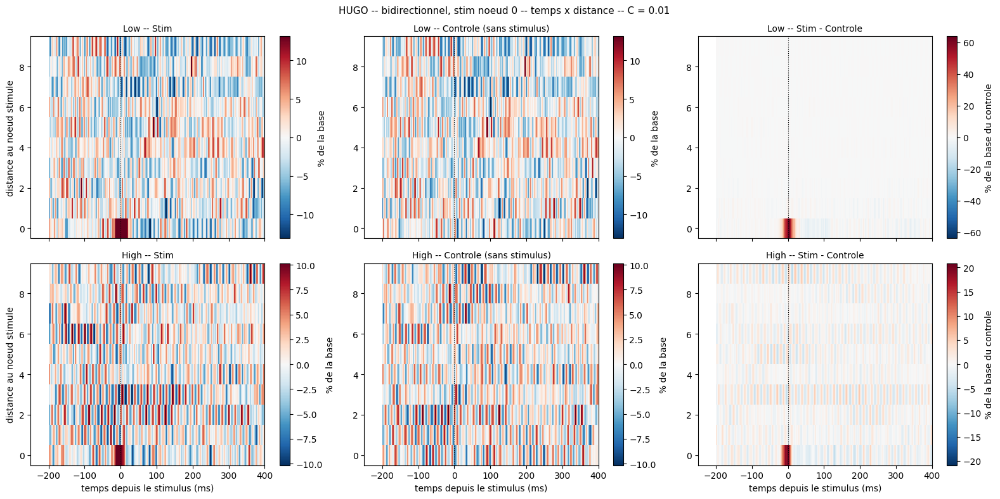

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim0_C0.01.png


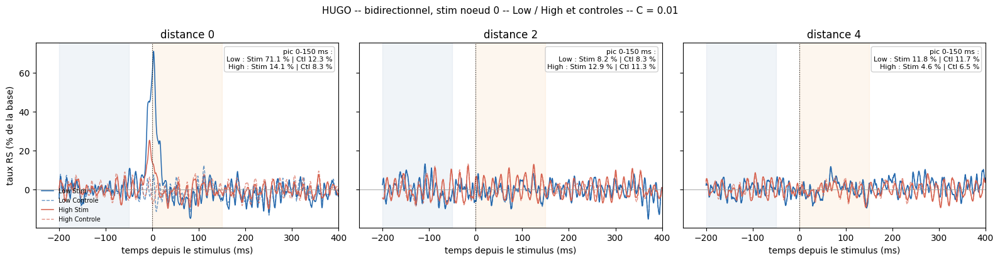

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim0_C0.01.png


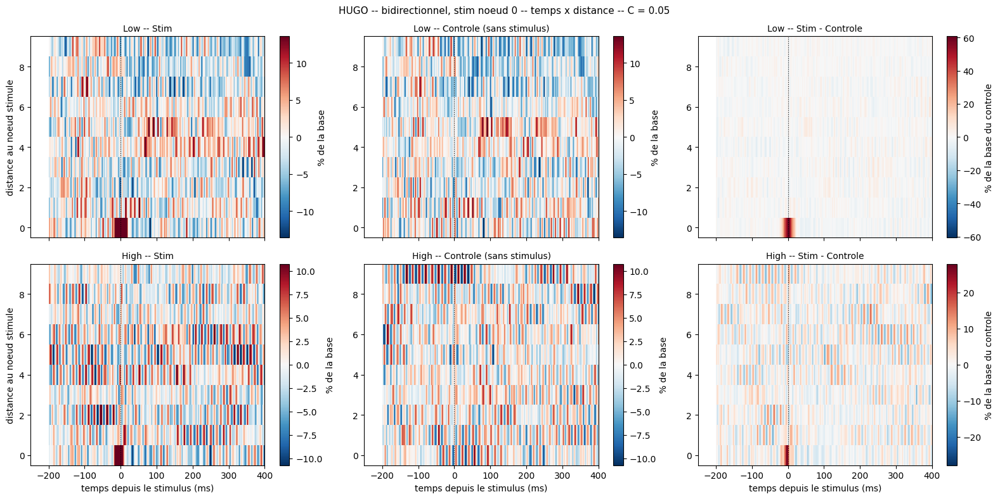

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim0_C0.05.png


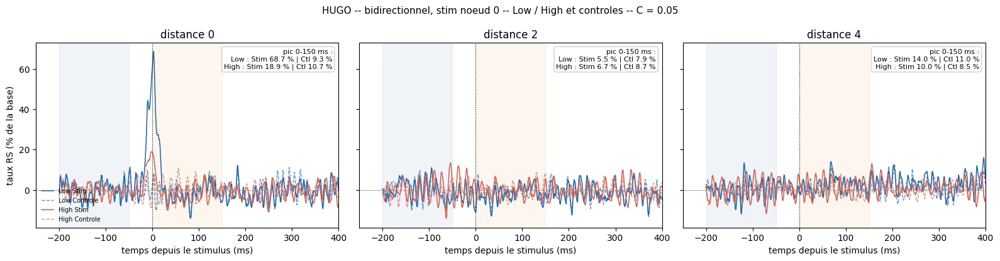

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim0_C0.05.png


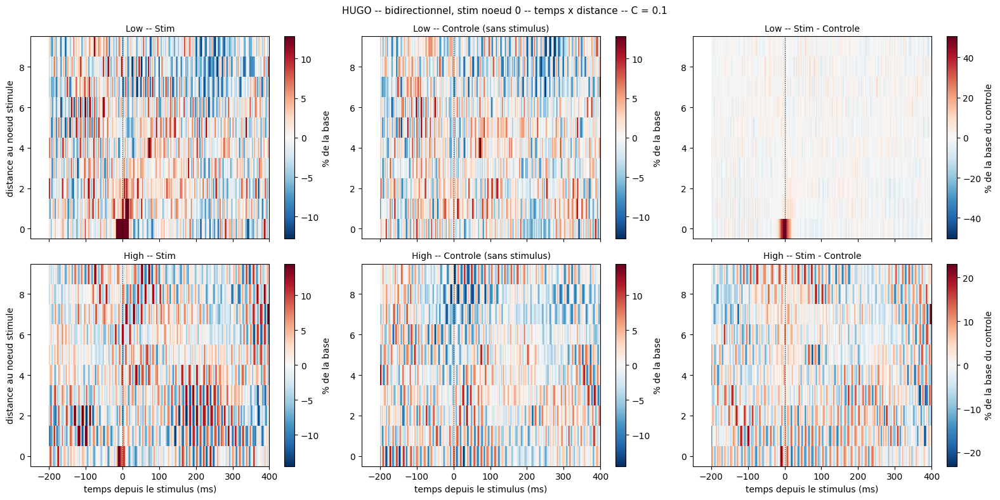

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim0_C0.1.png


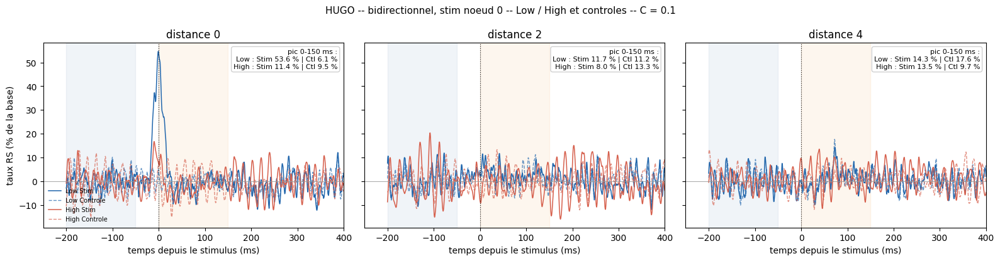

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim0_C0.1.png


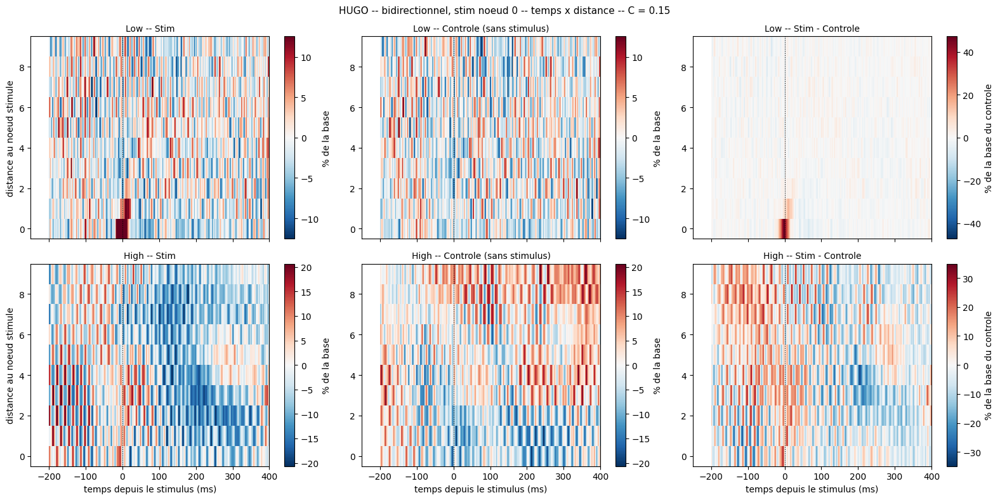

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim0_C0.15.png


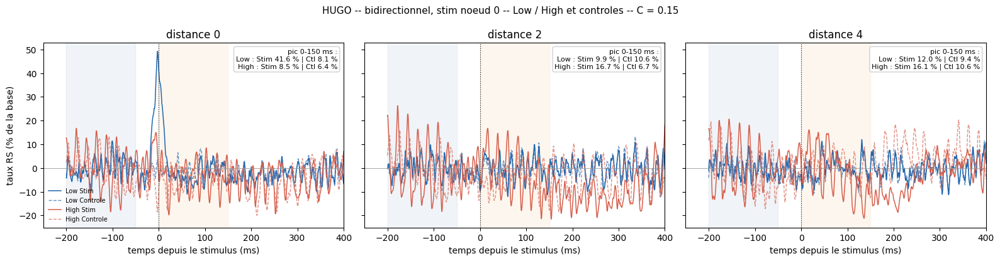

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim0_C0.15.png


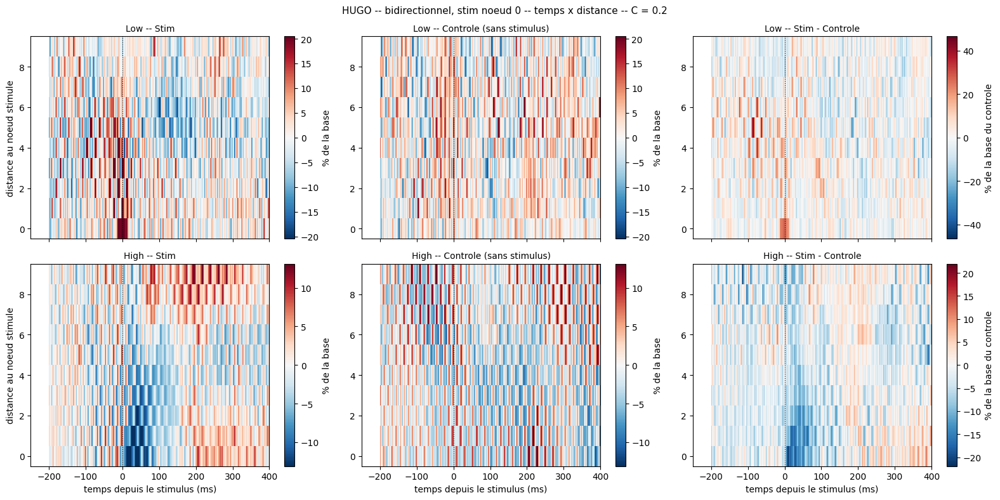

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim0_C0.2.png


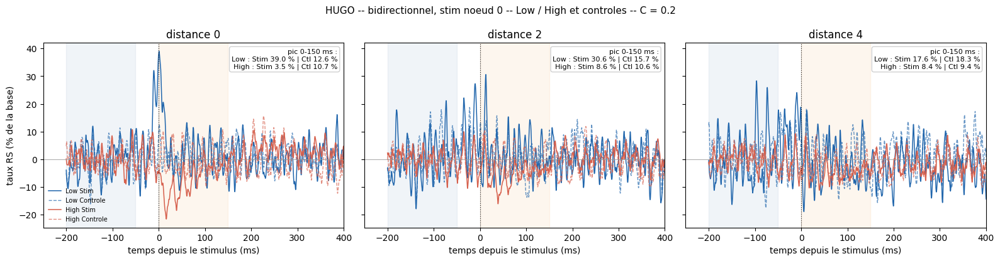

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim0_C0.2.png


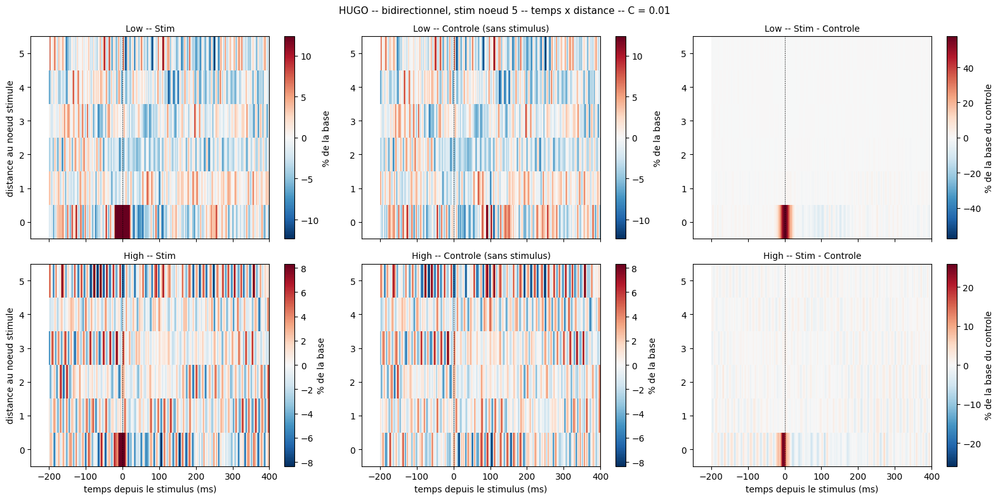

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim5_C0.01.png


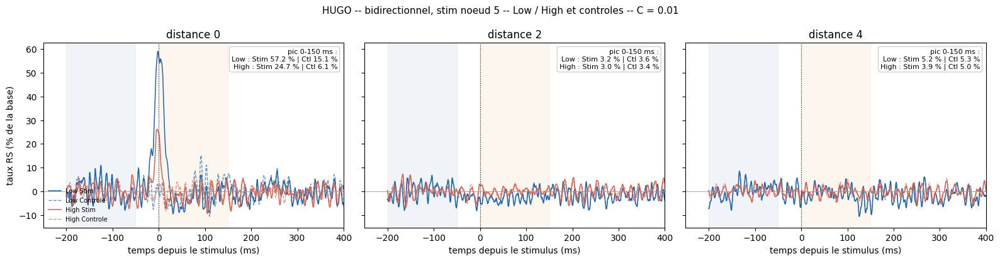

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim5_C0.01.png


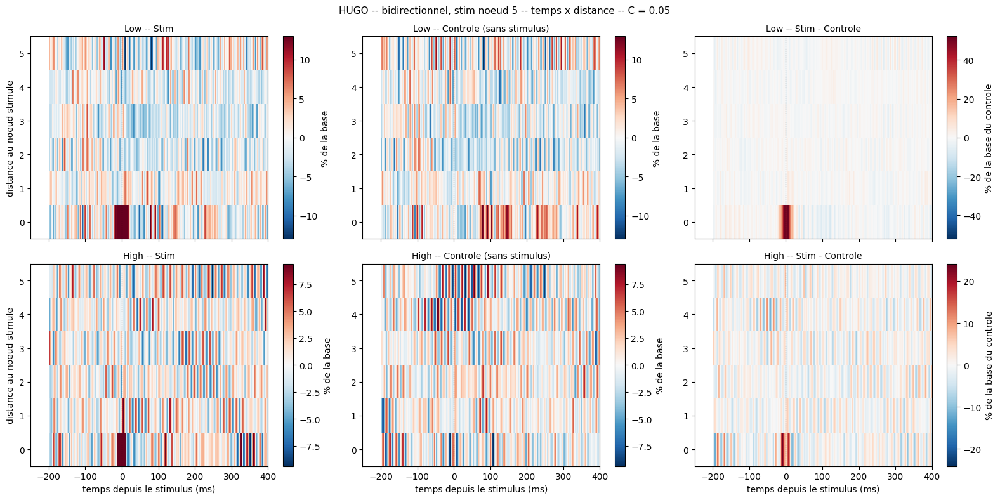

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim5_C0.05.png


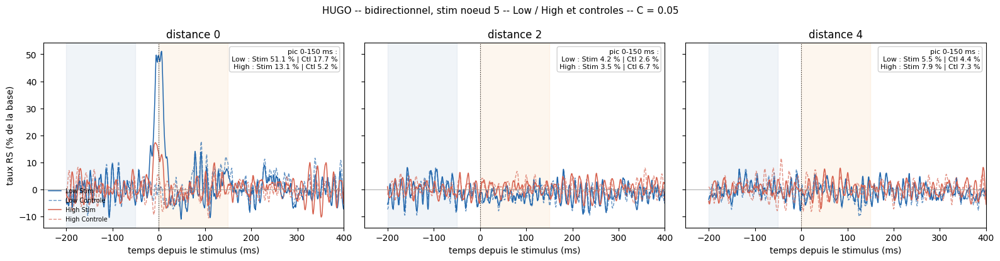

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim5_C0.05.png


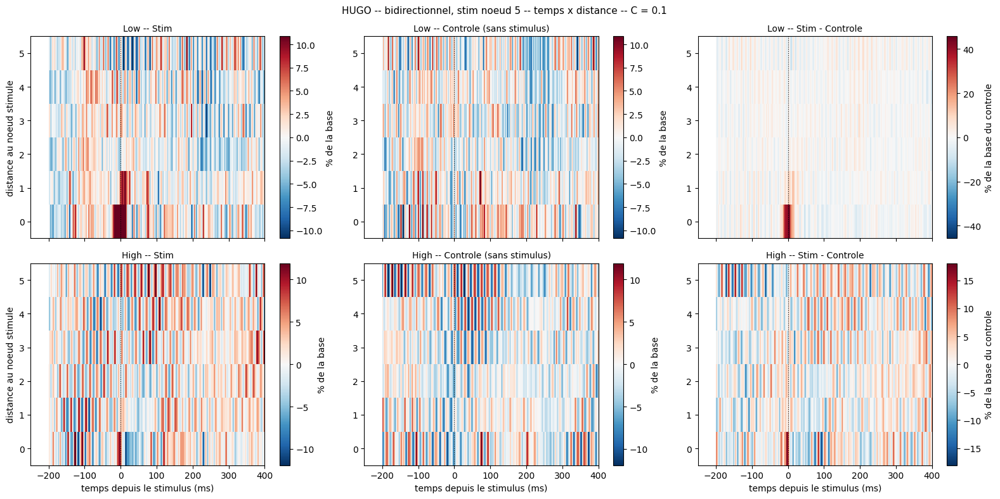

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim5_C0.1.png


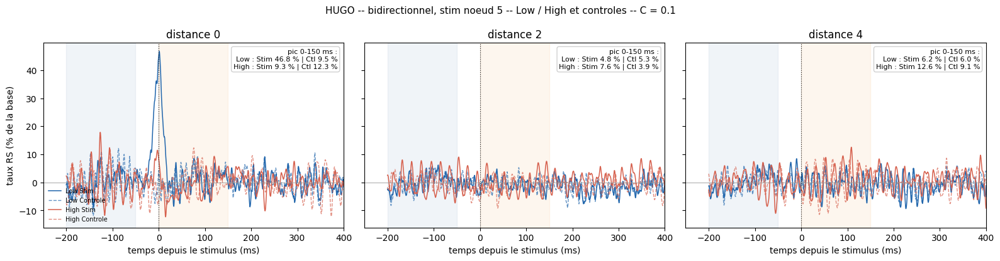

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim5_C0.1.png


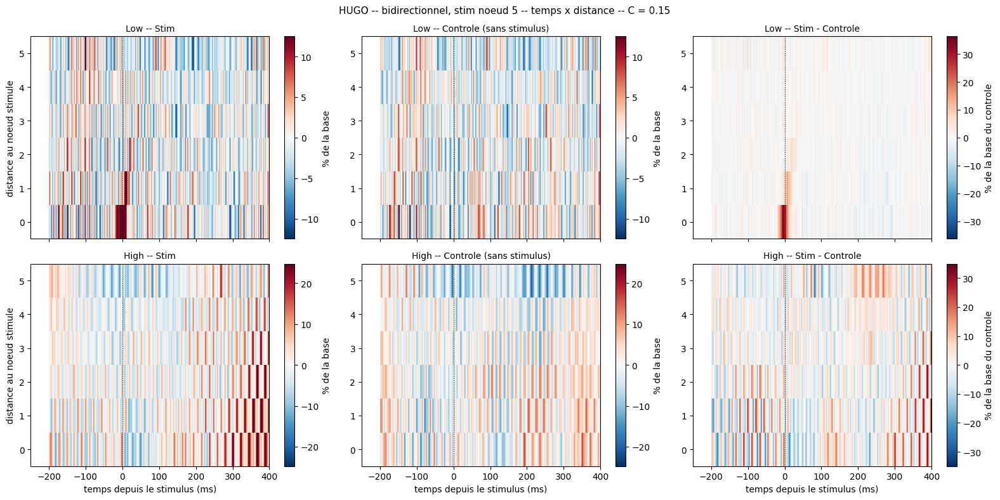

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim5_C0.15.png


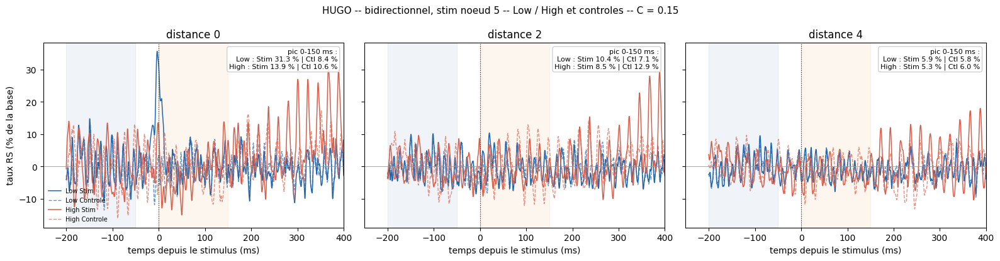

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim5_C0.15.png


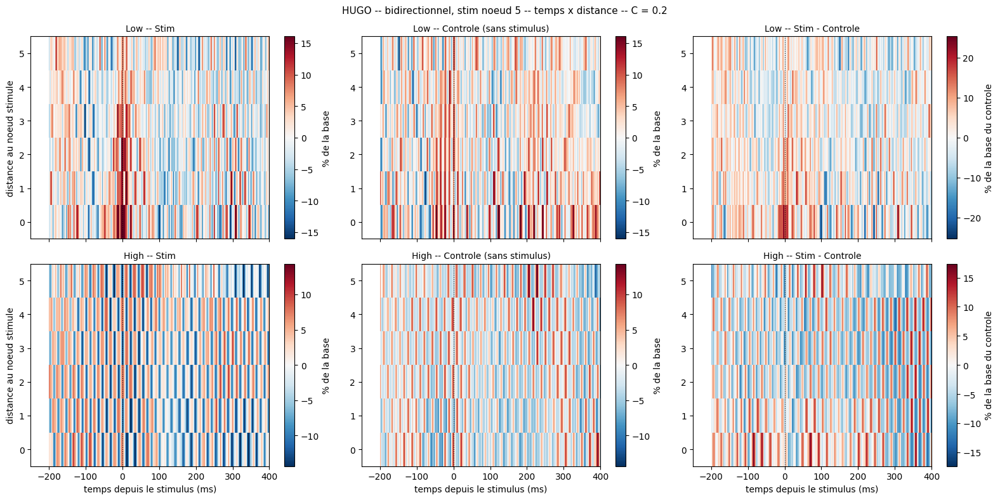

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_bidir_stim5_C0.2.png


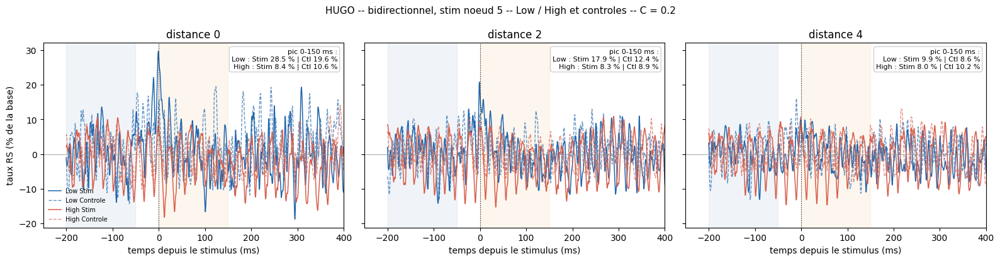

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_bidir_stim5_C0.2.png


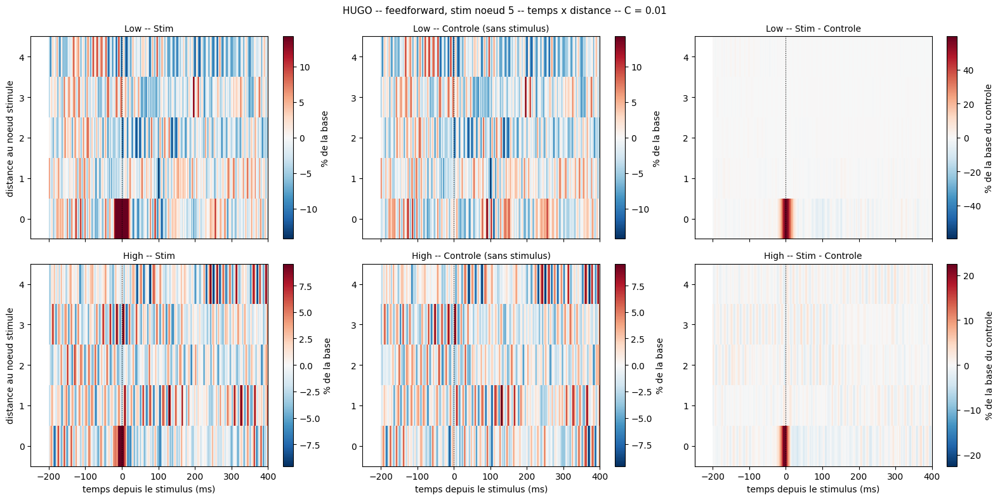

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim5_C0.01.png


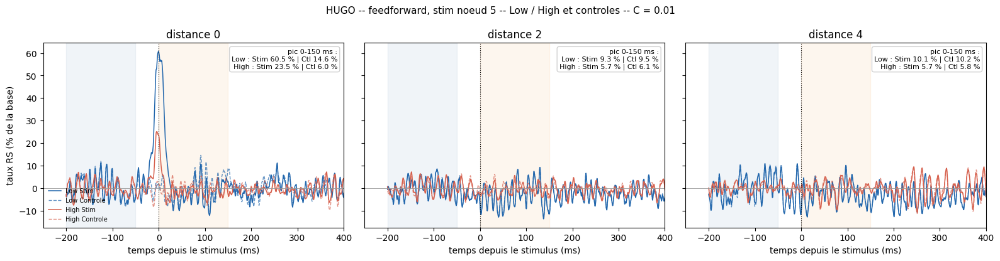

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim5_C0.01.png


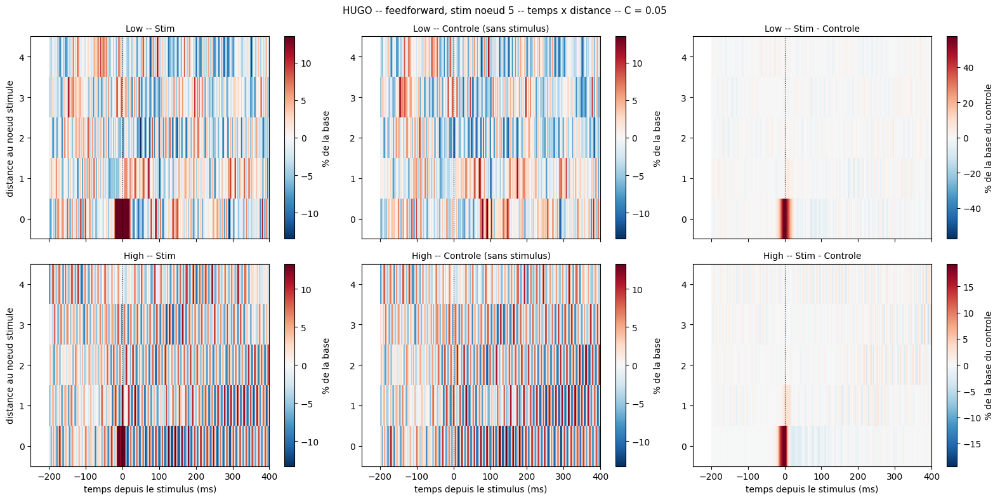

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim5_C0.05.png


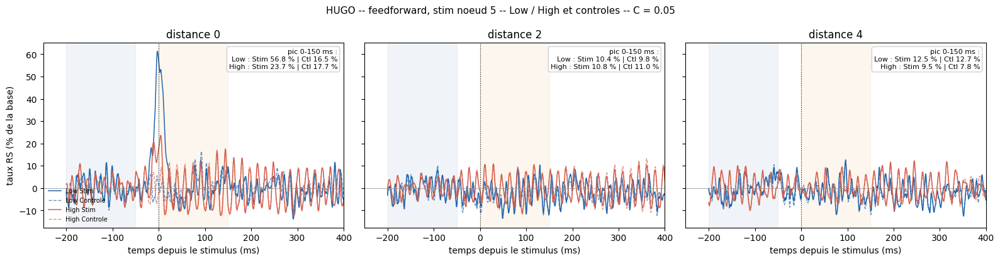

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim5_C0.05.png


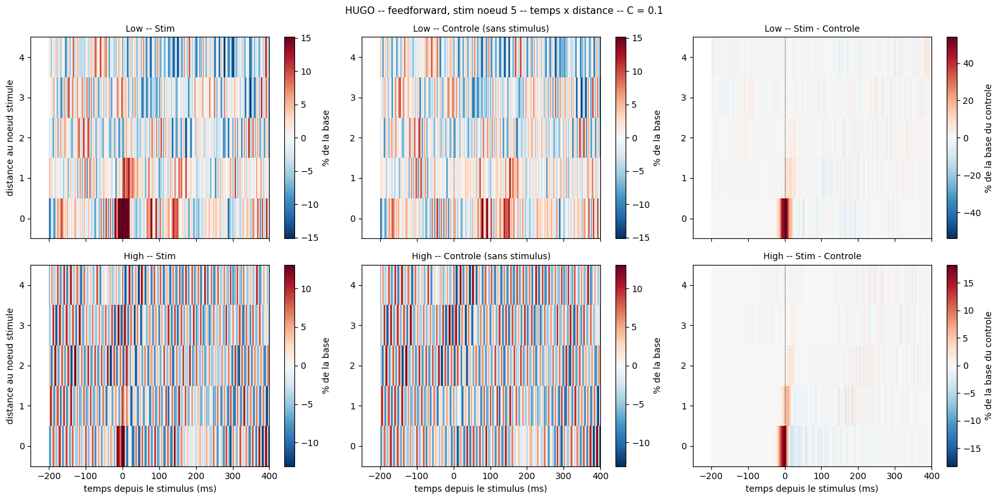

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim5_C0.1.png


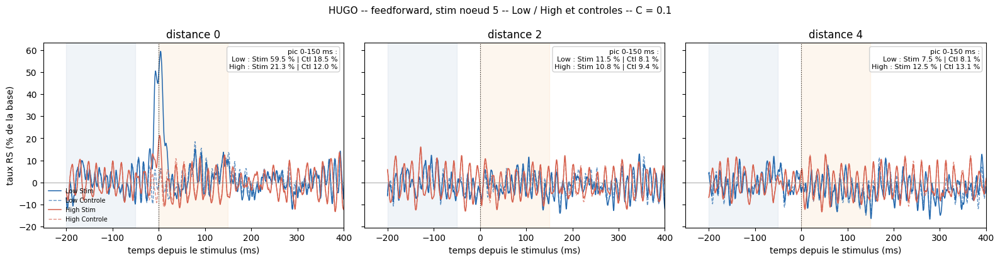

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim5_C0.1.png


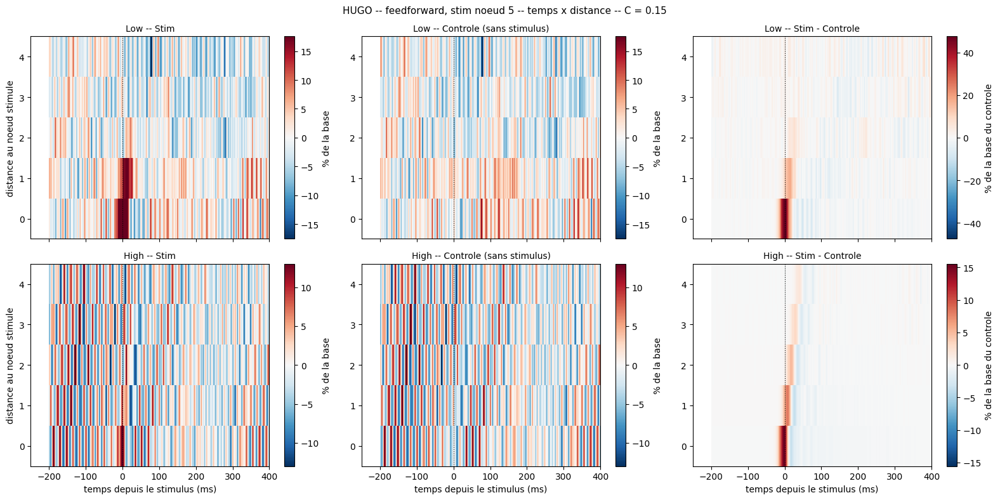

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim5_C0.15.png


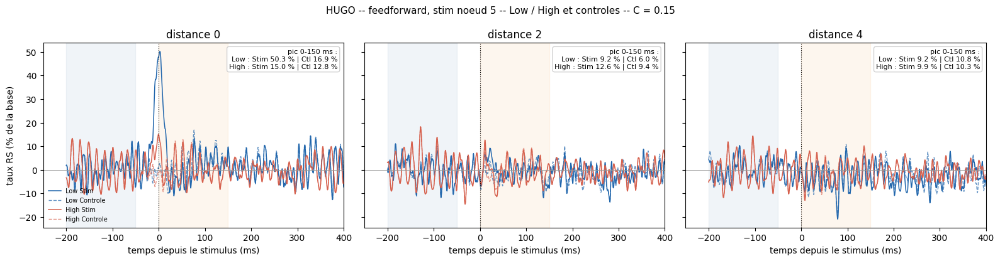

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim5_C0.15.png


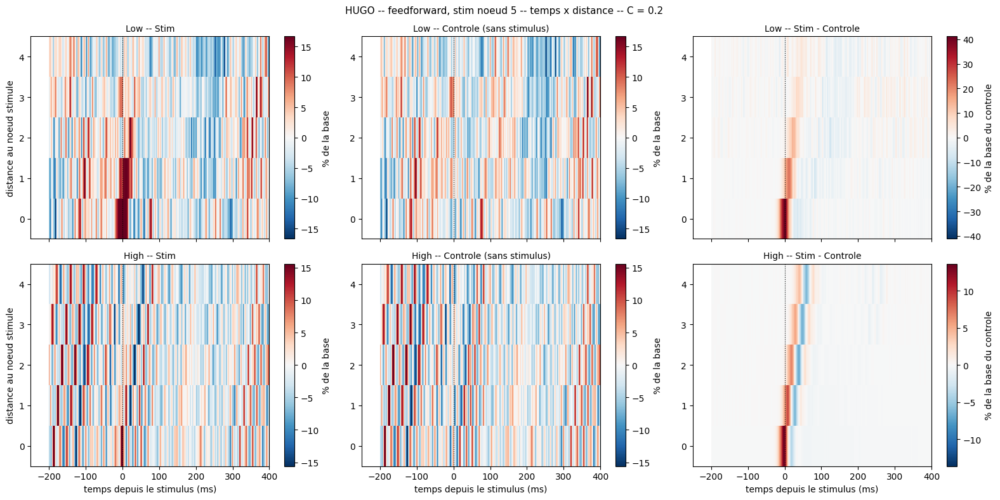

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim5_C0.2.png


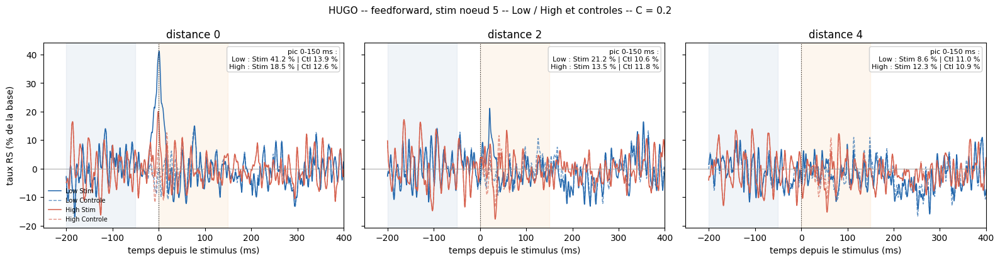

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim5_C0.2.png


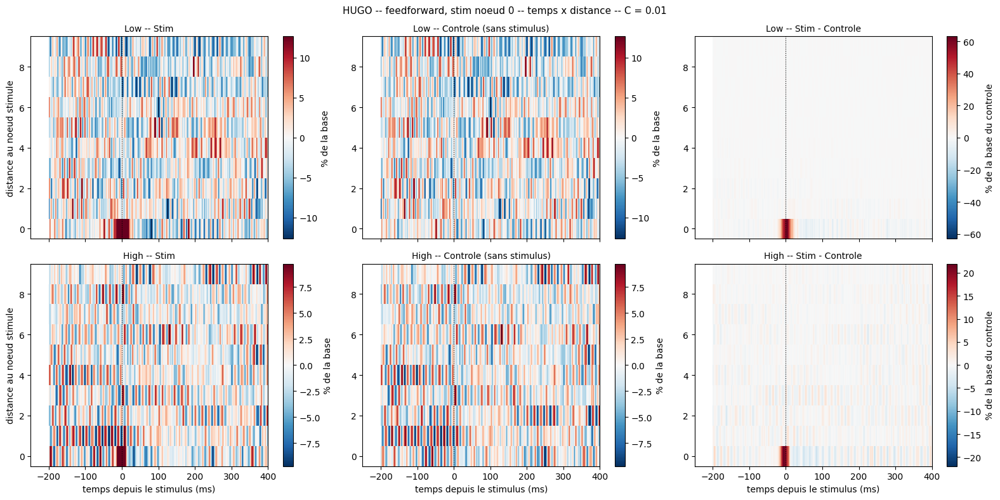

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim0_C0.01.png


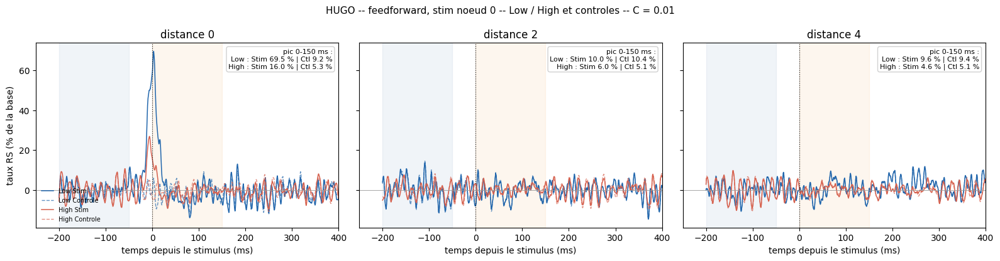

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim0_C0.01.png


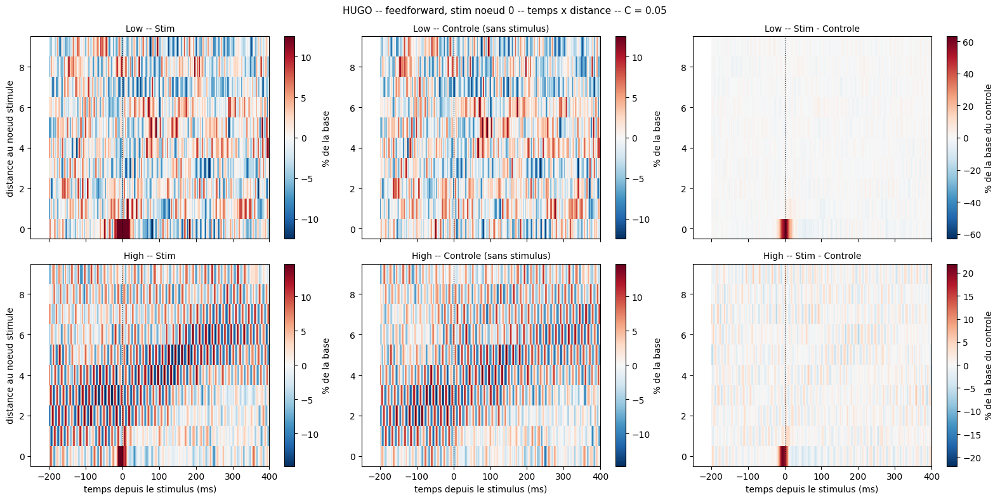

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim0_C0.05.png


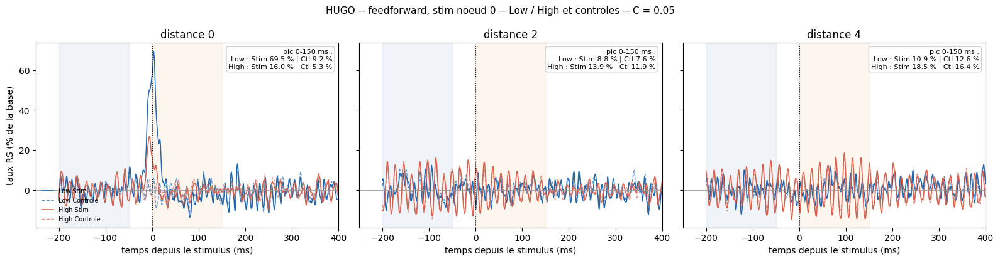

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim0_C0.05.png


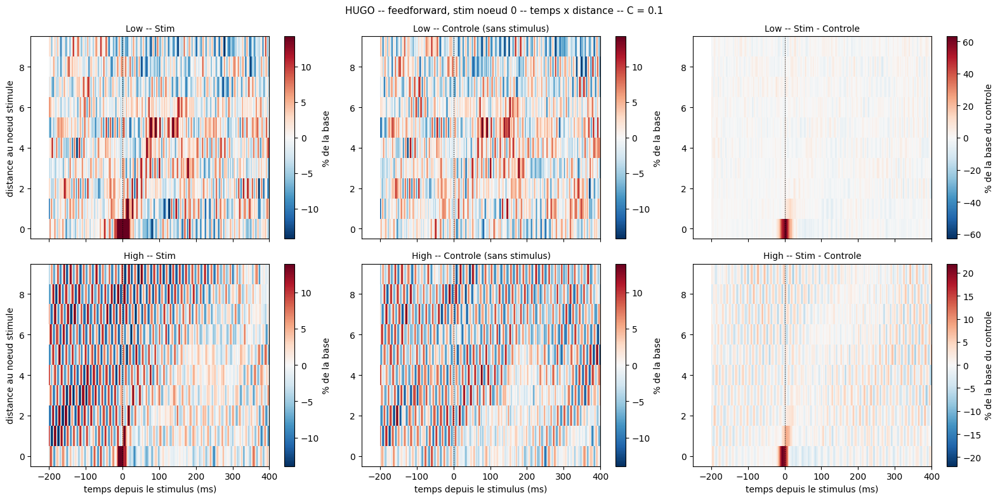

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim0_C0.1.png


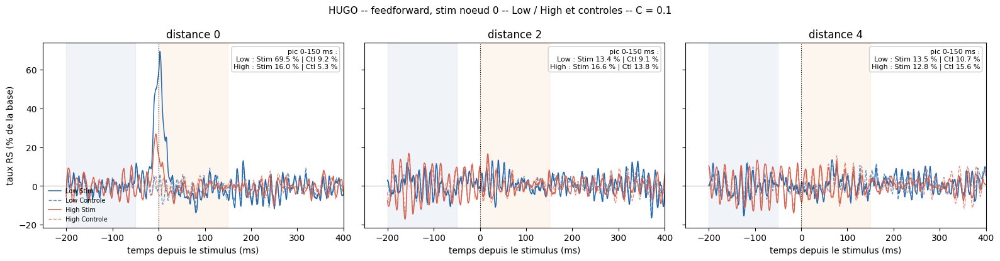

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim0_C0.1.png


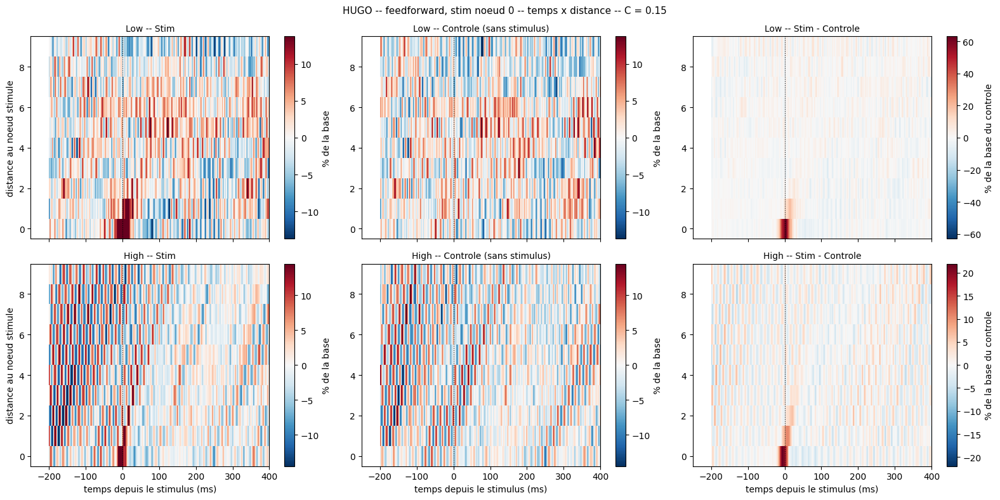

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim0_C0.15.png


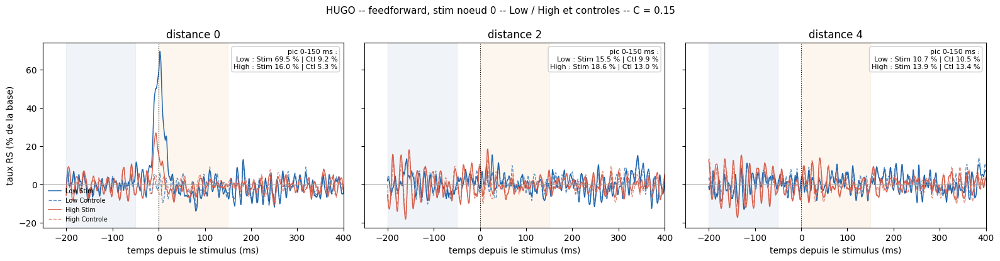

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim0_C0.15.png


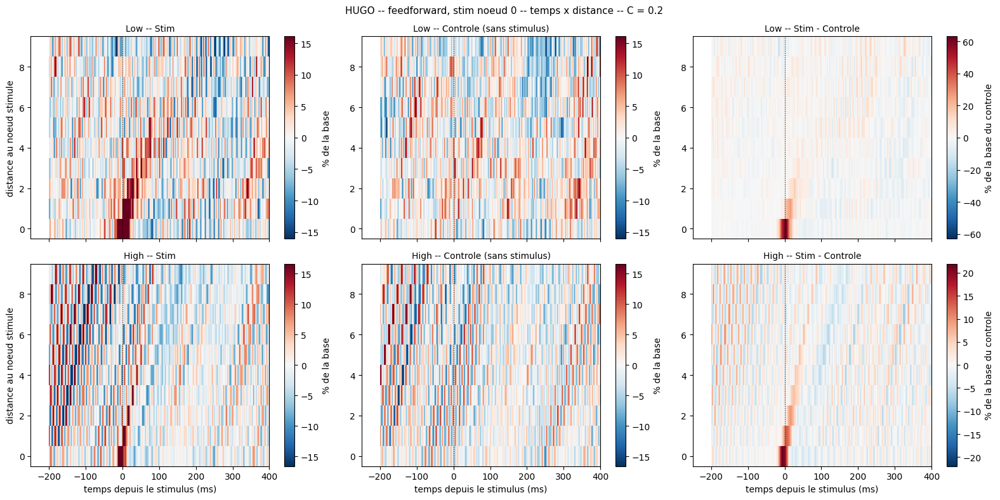

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_TIMEDIST_ALL_ff_stim0_C0.2.png


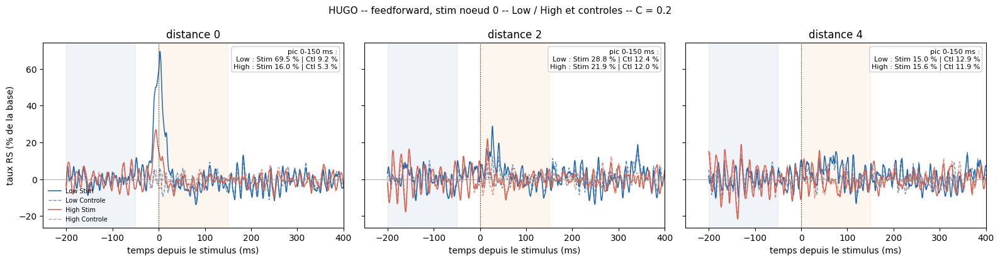

figure: figures_gamma\03\FIG_HUGO_CTRL_PCT_ALL_TRACES_ff_stim0_C0.2.png


In [21]:
RES, ETATS, COLS, CAS, NOMSD, LISTE_C = RES_CTL, list(COL), COL, CAS_CTL, NOMS, C_LIST_CTL
TITRE = TITRE_CTL
TEMPS = temps
def FICHIER(fig, nom):
    fp = os.path.join(FIGDIR, PREFIXE_FIG + "PCT_" + nom + ".png")
    fig.savefig(fp, dpi=110, bbox_inches="tight"); plt.show(); print("figure: " + fp)

C_ZIP = [A for A in LISTE_C if A <= 0.2]
for (geo, stim) in CAS:
    for A in C_ZIP:
        dispo = [l for l in ETATS if (geo, stim, A, l) in RES]
        if not dispo:
            continue
        # --- temps x distance
        fig, axs = plt.subplots(len(dispo), 3, figsize=(16, 4.0*len(dispo)), sharex=True, squeeze=False)
        for row, lab in enumerate(dispo):
            r = RES[(geo, stim, A, lab)]; t = TEMPS(r)
            ud, Ms = profil(r["rs_m"], geo, stim); _, Mc = profil(r["ctl_m"], geo, stim)
            Ps, Pc = en_pct(Ms, t), en_pct(Mc, t)
            _, Pd = profil(stim_moins_ctl_pct(r)[0], geo, stim)
            v = max(np.percentile(np.abs(np.concatenate([Ps.ravel(), Pc.ravel()])), 99.5), 1e-9)
            vd = max(np.abs(Pd).max(), 1e-9)
            for col, (M, titre, lim, cb) in enumerate([(Ps, "Stim", v, "% de la base"), (Pc, "Controle (sans stimulus)", v, "% de la base"),
                                                      (Pd, "Stim - Controle", vd, "% de la base du controle")]):
                ax = axs[row, col]
                im = ax.pcolormesh(t, ud, M.T, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="nearest")
                ax.axvline(0, color="k", ls=":", lw=0.8); ax.set_xlim(-250, 400)
                ax.set_title("%s -- %s%s" % (lab.split()[0], titre, "  (sature)" if sature(r) else ""), fontsize=10)
                fig.colorbar(im, ax=ax, label=cb)
                if col == 0: ax.set_ylabel("distance au noeud stimule")
                if row == len(dispo)-1: ax.set_xlabel("temps depuis le stimulus (ms)")
        fig.suptitle("%s%s, stim noeud %d -- temps x distance -- C = %g" % (TITRE, NOMSD[geo], stim, A), fontsize=11)
        plt.tight_layout(); FICHIER(fig, "TIMEDIST_ALL_%s_stim%d_C%g" % (geo, stim, A))

        fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
        for col, dd in enumerate((0, 2, 4)):
            ax = axs[col]; txt = []
            for lab in dispo:
                r = RES[(geo, stim, A, lab)]; t = TEMPS(r); _, fen = masques(t)
                ud, Ms = profil(r["rs_m"], geo, stim); _, Mc = profil(r["ctl_m"], geo, stim)
                if dd not in ud:
                    continue
                k = list(ud).index(dd)
                ps, pc = en_pct(Ms, t)[:, k], en_pct(Mc, t)[:, k]
                ax.plot(t, ps, "-", lw=1.1, color=COLS[lab], label=lab.split()[0] + " Stim")
                ax.plot(t, pc, "--", lw=1.0, color=COLS[lab], alpha=0.7, label=lab.split()[0] + " Controle")
                txt.append("%s : Stim %.1f %% | Ctl %.1f %%" % (lab.split()[0], ps[fen].max(), pc[fen].max()))
            ax.axvspan(*PRE_MS, color="#4C78A8", alpha=0.08); ax.axvspan(*FEN_MS, color="#F28E2B", alpha=0.08)
            ax.axvline(0, color="k", ls=":", lw=0.8); ax.axhline(0, color="0.6", lw=0.6); ax.set_xlim(-250, 400)
            ax.set_title("distance %d" % dd); ax.set_xlabel("temps depuis le stimulus (ms)")
            if txt:
                ax.text(0.98, 0.97, "pic 0-150 ms :\n" + "\n".join(txt), transform=ax.transAxes, ha="right", va="top", fontsize=8,
                        bbox=dict(boxstyle="round", fc="white", ec="0.8", alpha=0.9))
        axs[0].set_ylabel("taux RS (% de la base)"); axs[0].legend(fontsize=7, frameon=False, loc="lower left")
        fig.suptitle("%s%s, stim noeud %d -- Low / High et controles -- C = %g" % (TITRE, NOMSD[geo], stim, A), fontsize=11)
        plt.tight_layout(); FICHIER(fig, "ALL_TRACES_%s_stim%d_C%g" % (geo, stim, A))